# CDL-MDDNet for EEG-Based MDD Classification

## 1. Introduction and Project Objective

This project investigates the classification of Major Depressive Disorder (MDD) and Healthy Controls (HC) from resting-state EEG recordings using CDL-MDDNet. The notebook documents the dataset inspection, model and training setup, cross-validation experiments, participant-level evaluation, and diagnostic analysis.

The target is a binary diagnosis label: **0 = Healthy Control (HC)** and **1 = MDD**. Since multiple EEG epochs are available for each participant, both epoch-level predictions and participant-level aggregation are examined. The evaluation protocols are important because epochs from the same participant are correlated; a participant-disjoint split provides a stricter test of generalisation to unseen individuals.

The notebook contains exploratory diagnostics as well as several saved experimental runs. Existing saved outputs are retained; this documentation does not rerun training or alter reported metrics.

## 2. Environment and Project Setup

The project is run in Google Colab with its files stored in Google Drive. The setup below checks the runtime, mounts the project storage, and makes the source code and preprocessed EEG dataset available.

In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")
else:
    print("GPU not enabled. Check Runtime settings.")

PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
VRAM: 14.56 GB


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

path = "/content/drive/MyDrive"
print("Drive connected:", os.path.exists(path))

Drive connected: True


In [ ]:
import os

folder = "/content/drive/MyDrive/CDL-MDDNet"

print("Folder exists:", os.path.exists(folder))

if os.path.exists(folder):
    for file in os.listdir(folder):
        path = os.path.join(folder, file)
        if os.path.isfile(path):
            print(file, round(os.path.getsize(path) / (1024**2), 2), "MB")
        else:
            print(file, "(folder)")

Folder exists: True
modma_epochs.npz 1954.41 MB
cdl-mddnet-code.zip 0.08 MB


In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")
else:
    print("GPU not enabled. Go to Runtime > Change runtime type > T4 GPU.")

PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB


The project archive is extracted into the Colab working directory. The archive contains the model, data-processing, training, configuration, and test modules used by the experiments. The notebook uses the extracted implementation rather than redefining the network architecture inline.

In [ ]:
import os
import zipfile

drive_folder = "/content/drive/MyDrive/CDL-MDDNet"
project_zip = os.path.join(drive_folder, "cdl-mddnet-code.zip")
project_dir = "/content/CDL-MDDNet"

os.makedirs(project_dir, exist_ok=True)

with zipfile.ZipFile(project_zip, "r") as z:
    z.extractall(project_dir)

print("Project extracted successfully!")
print("Project files:", os.listdir(project_dir))

Project extracted successfully!
Project files: ['.github', '.pytest_cache', '.gitignore', 'reports', 'tests', 'pytest.ini', 'src', 'config', 'README.md', 'data', 'requirements.txt']


In [ ]:
import os
import shutil

source = "/content/drive/MyDrive/CDL-MDDNet/modma_epochs.npz"
destination = "/content/modma_epochs.npz"

if not os.path.exists(destination):
    print("Copying dataset. Please wait...")
    shutil.copy2(source, destination)
else:
    print("Dataset already copied.")

print("Dataset exists:", os.path.exists(destination))
print("Dataset size:", round(os.path.getsize(destination) / (1024**3), 2), "GB")

Copying dataset. Please wait...
Dataset exists: True
Dataset size: 1.91 GB


In [ ]:
%cd /content/CDL-MDDNet

print("Training runner exists:",
      os.path.exists("src/training/run_experiment.py"))

print("Model exists:",
      os.path.exists("src/models/cdl_mddnet.py"))

print("\nRequirements:")
with open("requirements.txt") as f:
    print(f.read())

/content/CDL-MDDNet
Training runner exists: True
Model exists: True

Requirements:
numpy
scipy
pandas
scikit-learn
matplotlib
mne
torch>=2.0
captum
pytest
python-pptx
# optional demo screen (Member 7)
# gradio



In [ ]:
import importlib.metadata as md
import torch

packages = [
    "numpy", "scipy", "pandas", "scikit-learn",
    "matplotlib", "mne", "captum", "pytest", "python-pptx"
]

print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

for package in packages:
    try:
        print(package, ":", md.version(package))
    except md.PackageNotFoundError:
        print(package, ": NOT INSTALLED")

PyTorch: 2.14.1+cu130
CUDA: True
numpy : 2.4.6
scipy : 1.16.3
pandas : 2.2.3
scikit-learn : 1.6.1
matplotlib : 3.10.0
mne : NOT INSTALLED
captum : NOT INSTALLED
pytest : 8.4.2
python-pptx : NOT INSTALLED


## 3. Dataset Description and Preparation

The experiment uses the **MODMA 128-channel resting-state EEG** dataset. The saved array file is an `.npz` container; the following inspection identifies its arrays and their dimensions before training.

In [ ]:
import numpy as np

dataset_path = "/content/modma_epochs.npz"

with np.load(dataset_path, allow_pickle=True) as data:
    print("Dataset keys:", data.files)

    for key in data.files:
        arr = data[key]
        print(
            f"{key}: shape={arr.shape}, dtype={arr.dtype}"
        )
        del arr

Dataset keys: ['X', 'y', 'subject_id', 'ch_names', 'subject_str_id']
X: shape=(4002, 128, 1000), dtype=float32
y: shape=(4002,), dtype=int64
subject_id: shape=(4002,), dtype=int64
ch_names: shape=(128,), dtype=<U8
subject_str_id: shape=(4002,), dtype=<U16


In [ ]:
%cd /content/CDL-MDDNet
!python -m src.training.run_experiment --help

/content/CDL-MDDNet
usage: run_experiment.py [-h] [--config CONFIG] [--model MODEL]
                         [--protocol {kfold10,loso}] [--experiment EXPERIMENT]
                         [--data DATA] [--runs-dir RUNS_DIR]
                         [--n-folds N_FOLDS] [--val-fraction VAL_FRACTION]
                         [--epochs EPOCHS] [--batch-size BATCH_SIZE] [--lr LR]
                         [--weight-decay WEIGHT_DECAY] [--patience PATIENCE]
                         [--seed SEED] [--split-seed SPLIT_SEED]
                         [--device DEVICE] [--num-workers NUM_WORKERS]
                         [--no-amp] [--no-class-weights] [--use-dann |
                         --no-dann] [--dann-gamma DANN_GAMMA]
                         [--dann-weight DANN_WEIGHT]
                         [--channels CHANNELS [CHANNELS ...]]
                         [--channel-ranking CHANNEL_RANKING]
                         [--top-k-channels TOP_K_CHANNELS]
                         [--folds FOLDS [

The label and participant inspection establishes the class distribution and the number of epochs contributed by each participant. The stored labels use 0 for HC and 1 for MDD. Participant-level label consistency is checked separately below so that a participant is not assigned conflicting diagnoses across their epochs.

In [ ]:
import numpy as np

with np.load("/content/modma_epochs.npz", allow_pickle=True) as data:
    y = data["y"]
    subjects = data["subject_id"]
    subject_names = data["subject_str_id"]

print("Label distribution:")
labels, counts = np.unique(y, return_counts=True)
for label, count in zip(labels, counts):
    print(f"Label {label}: {count} samples")

print("\nUnique participants:", len(np.unique(subjects)))
print("Participant IDs:", np.unique(subjects))

print("\nSamples per participant:")
for sid in np.unique(subjects):
    count = np.sum(subjects == sid)
    print(f"Subject {sid}: {count} samples")

Label distribution:
Label 0: 2192 samples
Label 1: 1810 samples

Unique participants: 53
Participant IDs: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52]

Samples per participant:
Subject 0: 75 samples
Subject 1: 75 samples
Subject 2: 75 samples
Subject 3: 78 samples
Subject 4: 82 samples
Subject 5: 75 samples
Subject 6: 75 samples
Subject 7: 75 samples
Subject 8: 75 samples
Subject 9: 75 samples
Subject 10: 75 samples
Subject 11: 75 samples
Subject 12: 75 samples
Subject 13: 75 samples
Subject 14: 75 samples
Subject 15: 75 samples
Subject 16: 75 samples
Subject 17: 75 samples
Subject 18: 75 samples
Subject 19: 75 samples
Subject 20: 75 samples
Subject 21: 75 samples
Subject 22: 75 samples
Subject 23: 75 samples
Subject 24: 75 samples
Subject 25: 76 samples
Subject 26: 75 samples
Subject 27: 75 samples
Subject 28: 75 samples
Subject 29: 75 samples
Subject 30: 75 samples
Su

In [ ]:
%cd /content/CDL-MDDNet

!grep -R -nE "^(import|from) (mne|captum|pptx|torch|numpy|scipy|pandas|sklearn)" src

/content/CDL-MDDNet
src/eval/benchmark.py:15:import torch
src/eval/benchmark.py:16:from torch import nn
src/eval/update_slides.py:10:from pptx import Presentation
src/training/config.py:16:import numpy as np
src/training/config.py:17:import torch
src/training/config.py:18:from torch import nn
src/training/trainer.py:14:import numpy as np
src/training/trainer.py:15:from sklearn.metrics import roc_auc_score
src/training/trainer.py:16:import torch
src/training/trainer.py:17:from torch import nn
src/training/trainer.py:18:from torch.utils.data import DataLoader, TensorDataset
src/training/splits.py:15:import numpy as np
src/training/splits.py:16:from sklearn.model_selection import StratifiedKFold
src/training/run_experiment.py:27:import numpy as np
src/training/run_experiment.py:28:import torch
src/models/cdl_mddnet.py:23:import torch
src/models/cdl_mddnet.py:24:import torch.nn as nn
src/models/cdl_mddnet.py:25:from torch.autograd import Function
src/data/normalize.py:15:import numpy as np

In [ ]:
import os

runs_dir = "/content/drive/MyDrive/CDL-MDDNet/runs"
os.makedirs(runs_dir, exist_ok=True)

print("Checkpoint directory:", runs_dir)
print("Directory exists:", os.path.exists(runs_dir))

Checkpoint directory: /content/drive/MyDrive/CDL-MDDNet/runs
Directory exists: True


The JSON configuration is the source of the training settings for this run. It records the selected model, validation protocol, fold count, optimisation settings, and whether domain-adversarial training is enabled. The values printed here should be interpreted as the configuration actually loaded by the training runner, not as generic recommended values.

In [ ]:
import json

config_path = "/content/CDL-MDDNet/config/train_config.json"

with open(config_path) as f:
    config = json.load(f)

print(json.dumps(config, indent=4))

{
    "experiment": "cdl_mddnet",
    "model": "src.models.cdl_mddnet:CDLMDDNet",
    "protocol": "kfold10",
    "data_path": null,
    "runs_dir": "runs",
    "n_folds": 10,
    "val_fraction": 0.15,
    "seed": 42,
    "split_seed": 0,
    "epochs": 60,
    "batch_size": 64,
    "lr": 0.001,
    "weight_decay": 0.0001,
    "optimizer": "adamw",
    "scheduler": "cosine",
    "early_stopping_patience": 12,
    "early_stopping_min_delta": 0.0001,
    "class_weighted_loss": true,
    "grad_clip_norm": 1.0,
    "use_dann": true,
    "dann_gamma": 10.0,
    "dann_loss_weight": 1.0,
    "use_amp": true,
    "deterministic": true,
    "device": "auto",
    "num_workers": 0,
    "n_classes": 2
}


A participant must have one diagnosis label throughout the dataset. This check is important because participant-level aggregation and subject-disjoint validation assume that the diagnosis is stable for all epochs belonging to the same person.

In [ ]:
import numpy as np

with np.load("/content/modma_epochs.npz", allow_pickle=True) as data:
    y = data["y"]
    subjects = data["subject_id"]

print("Checking diagnosis consistency per participant...\n")

inconsistent = []

for sid in np.unique(subjects):
    subject_labels = np.unique(y[subjects == sid])

    print(f"Subject {sid}: labels = {subject_labels}")

    if len(subject_labels) != 1:
        inconsistent.append(sid)

print("\nInconsistent participants:", inconsistent)

if len(inconsistent) == 0:
    print("PASS: Every participant has a consistent diagnosis label.")
else:
    print("WARNING: Investigate these participants before training.")

Checking diagnosis consistency per participant...

Subject 0: labels = [1]
Subject 1: labels = [1]
Subject 2: labels = [1]
Subject 3: labels = [1]
Subject 4: labels = [1]
Subject 5: labels = [1]
Subject 6: labels = [1]
Subject 7: labels = [1]
Subject 8: labels = [1]
Subject 9: labels = [1]
Subject 10: labels = [1]
Subject 11: labels = [1]
Subject 12: labels = [1]
Subject 13: labels = [1]
Subject 14: labels = [1]
Subject 15: labels = [1]
Subject 16: labels = [1]
Subject 17: labels = [1]
Subject 18: labels = [1]
Subject 19: labels = [1]
Subject 20: labels = [1]
Subject 21: labels = [1]
Subject 22: labels = [1]
Subject 23: labels = [1]
Subject 24: labels = [0]
Subject 25: labels = [0]
Subject 26: labels = [0]
Subject 27: labels = [0]
Subject 28: labels = [0]
Subject 29: labels = [0]
Subject 30: labels = [0]
Subject 31: labels = [0]
Subject 32: labels = [0]
Subject 33: labels = [0]
Subject 34: labels = [0]
Subject 35: labels = [0]
Subject 36: labels = [0]
Subject 37: labels = [0]
Subject 3

## 4. CDL-MDDNet Implementation

The next inspections locate the training and experiment functions in the source package. The model itself is imported as `CDLMDDNet`; its input is an EEG epoch with channel and time dimensions. The saved experiment metadata reports 128 input channels, 1,000 samples per epoch, and 25,627 trainable parameters for the configured model. The notebook does not redefine or modify the architecture.

In [ ]:
%cd /content/CDL-MDDNet

!grep -nE "^(class |def |async def )" src/training/trainer.py

/content/CDL-MDDNet
52:class EarlyStopping:
95:def _seed_worker(worker_id: int) -> None:
101:def _make_loader(
140:def _compute_class_weights(y_train: np.ndarray, n_classes: int) -> Optional[torch.Tensor]:
149:def _safe_auc(y_true: np.ndarray, p_pos: np.ndarray) -> float:
159:def _evaluate_loader(
197:def _save_state_dict_cpu(
210:def _remap_training_subjects(
231:def _validate_train_resume_checkpoint(
266:def _load_checkpoint_into_model(
295:def train_fold(


In [ ]:
!grep -nE "^(class |def |async def )" src/training/run_experiment.py

44:def load_processed_dataset(
74:def select_channels(
162:def parse_fold_selection(spec: Optional[Sequence[str]], total_folds: int) -> Optional[set[int]]:
186:def _hardware_info(device: torch.device) -> Dict[str, Any]:
226:def _validate_resume_compatibility(
264:def run_experiment(
461:def build_arg_parser() -> argparse.ArgumentParser:
509:def main(argv: Optional[Sequence[str]] = None) -> None:


The import checks confirm that the model, configuration, trainer, and split utilities can be loaded from the project package. The trainer and split module names are also listed to make the implemented workflow inspectable.

In [ ]:
import torch
from src.models.cdl_mddnet import CDLMDDNet
from src.training.config import TrainConfig
import src.training.trainer as trainer_module
import src.training.splits as splits_module

print("Model import: PASS")
print("Config import: PASS")
print("Trainer module import: PASS")
print("Splits module import: PASS")

print("\nTrainer module names:")
print([name for name in dir(trainer_module) if not name.startswith("_")])

print("\nSplit module names:")
print([name for name in dir(splits_module) if not name.startswith("_")])

print("\nCUDA:", torch.cuda.is_available())

Model import: PASS
Config import: PASS
Trainer module import: PASS
Splits module import: PASS

Trainer module names:
['Any', 'Callable', 'DataLoader', 'Dict', 'EarlyStopping', 'List', 'Optional', 'Path', 'Sequence', 'TRAIN_CKPT_FILENAME', 'TRAIN_RESUME_COMPAT_KEYS', 'TensorDataset', 'TrainConfig', 'Tuple', 'Union', 'annotations', 'apply_normalizer', 'build_model', 'csv', 'dann_lambda', 'fit_normalizer', 'gc', 'json', 'make_val_split', 'math', 'nn', 'np', 'random', 'resolve_device', 'roc_auc_score', 'set_seed', 'time', 'torch', 'train_fold']

Split module names:
['Iterator', 'Optional', 'StratifiedKFold', 'Tuple', 'annotations', 'kfold_splits', 'loso_splits', 'make_val_split', 'np']

CUDA: True


The notebook confirms the model class, input dimensions, and parameter count, but it does not print the internal layer-by-layer definition of `CDLMDDNet`. The architecture is therefore kept exactly as implemented in `src/models/cdl_mddnet.py`; no unverified claims about specific convolution, pooling, or attention blocks are added here. The available metadata identifies 128 channels, 1,000 time samples, two diagnosis classes, and 25,627 trainable parameters for the recorded ERM experiment.

### Architecture details and implementation boundary

The notebook imports `CDLMDDNet` from `src/models/cdl_mddnet.py`; it does not contain that class definition. The separate `cdl-mddnet-code.zip` archive is referenced as a file on the original Colab Drive, but that archive was not included with this notebook upload. Therefore, the exact sequence of layers, their kernel sizes, channel widths, activation functions, normalisation, pooling, and classifier dimensions cannot be verified from the supplied file alone.

The verified information available here is that the experiment uses an input shaped `(128, 1000)` per EEG epoch, predicts two classes (HC and MDD), and records 25,627 trainable parameters for the configured `CDLMDDNet`. The model is instantiated by the project training code rather than redefined in this notebook. No layer-by-layer description is added until the actual `src/models/cdl_mddnet.py` source is available; guessing those details would risk documenting a different architecture.


In [ ]:
import inspect
from src.training.trainer import train_fold

print("Training function:", train_fold.__name__)
print("Function signature:")
print(inspect.signature(train_fold))

Training function: train_fold
Function signature:
(fold_idx: 'int', X: 'np.ndarray', y: 'np.ndarray', subject_ids: 'np.ndarray', train_idx: 'np.ndarray', test_idx: 'np.ndarray', cfg: 'TrainConfig', output_dir: 'Union[str, Path]', ch_names: 'Optional[Sequence[str]]' = None, epoch_callback: 'Optional[Callable[[Dict[str, Any]], None]]' = None, resume: 'bool' = False) -> 'Dict[str, Any]'


The repository test suite is run as a software-integrity check. These tests check implementation behaviour; they are not measures of diagnostic performance on the held-out EEG participants.

In [ ]:
%cd /content/CDL-MDDNet
!pytest -q

/content/CDL-MDDNet
........................................................................ [ 77%]
.....................                                                    [100%]
93 passed in 35.73s


In [ ]:
!sed -n '1,220p' src/training/splits.py

"""Participant-level cross-validation splits for CDL-MDDNet.

Strictly enforces subject-disjoint splits so no participant's epochs ever appear
in both training and evaluation sets.

Contracts (README.md & tests/test_no_subject_leakage.py):
    kfold_splits(subject_ids, n_folds=10, seed=0) -> yields (train_idx, test_idx)
    loso_splits(subject_ids)                       -> yields (train_idx, test_idx)
"""

from __future__ import annotations

from typing import Iterator, Optional, Tuple

import numpy as np
from sklearn.model_selection import StratifiedKFold


def _validate_subject_ids(subject_ids: np.ndarray) -> np.ndarray:
    if subject_ids is None:
        raise ValueError("subject_ids must not be None.")
    sids = np.asarray(subject_ids)
    if sids.ndim != 1 or sids.size == 0:
        raise ValueError(
            f"subject_ids must be a non-empty 1D array, got shape {sids.shape}."
        )
    if np.issubdtype(sids.dtype, np.floating) and np.isnan(sids).any():
        raise Valu

In [ ]:
!sed -n '264,460p' src/training/run_experiment.py

def run_experiment(
    cfg: TrainConfig,
    channels: Optional[Sequence[str]] = None,
    channel_ranking_csv: Optional[Union[str, Path]] = None,
    top_k_channels: Optional[int] = None,
    fold_subset: Optional[Sequence[str]] = None,
    resume: bool = False,
    overwrite: bool = False,
    verbose: bool = True,
) -> Dict[str, Any]:
    """Run 10-fold CV or 53-fold LOSO experiment and save fold artifacts under `runs/<experiment>/`."""
    cfg.validate()
    # Configure reproducibility before resolving/initializing CUDA context.
    seed_status = set_seed(cfg.seed, deterministic=cfg.deterministic)

    X, y, subject_id, ch_names, resolved_data = load_processed_dataset(cfg.data_path)
    X, selected_ch_names, selected_ch_idx = select_channels(
        X,
        ch_names,
        channels=channels,
        channel_ranking_csv=channel_ranking_csv,
        top_k_channels=top_k_channels,
    )

    device = resolve_device(cfg.device)
    hw = _hardware_info(device)

    # Verify model

## 5. Training Methodology and Configuration

The training source is inspected to understand how folds are formed, how the trainer handles validation, and how checkpoints are saved. In the trainer, normalisation statistics are fitted using only the training subset and then applied to validation and test data. This prevents information from the held-out subsets from contributing to the fitted normaliser.

In [ ]:
import os

runs_dir = "/content/drive/MyDrive/CDL-MDDNet/runs"
print("Drive checkpoint directory exists:", os.path.exists(runs_dir))
print("Existing contents:", os.listdir(runs_dir))

Drive checkpoint directory exists: True
Existing contents: []


In [ ]:
%cd /content/CDL-MDDNet

!sed -n '295,520p' src/training/trainer.py

/content/CDL-MDDNet
def train_fold(
    fold_idx: int,
    X: np.ndarray,
    y: np.ndarray,
    subject_ids: np.ndarray,
    train_idx: np.ndarray,
    test_idx: np.ndarray,
    cfg: TrainConfig,
    output_dir: Union[str, Path],
    ch_names: Optional[Sequence[str]] = None,
    epoch_callback: Optional[Callable[[Dict[str, Any]], None]] = None,
    resume: bool = False,
) -> Dict[str, Any]:
    """Train, early-stop, checkpoint, and evaluate a single cross-validation fold.

    Expected model interface:
    - Input: `(batch_size, n_channels, n_samples)` (e.g. `(B, 128, 1000)`)
    - Output: `(batch_size, 2)` logits (or `(class_logits, subject_logits)` from
      `forward_train(x, lambd)` when `cfg.use_dann=True`)
    - Labels: `(batch_size,)` binary integers (`0 = Healthy`, `1 = MDD`)

    Outputs under `output_dir`:
    - `model.pt`: inference-only CPU `state_dict` (never stores `subject_head.*`)
    - `train_checkpoint.pt`: full training-resume checkpoint (includes `subject_head`,
  

In [ ]:
!sed -n '461,560p' src/training/run_experiment.py

def build_arg_parser() -> argparse.ArgumentParser:
    ap = argparse.ArgumentParser(description="Run CDL-MDDNet / baseline EEG cross-validation.")
    ap.add_argument("--config", type=str, default=None, help="Path to JSON training config.")
    ap.add_argument("--model", type=str, default=None, help="'dummy' or module:ClassName")
    ap.add_argument("--protocol", type=str, choices=["kfold10", "loso"], default=None)
    ap.add_argument("--experiment", type=str, default=None, help="Output folder name under --runs-dir.")
    ap.add_argument("--data", type=str, default=None, help="Path to modma_epochs.npz.")
    ap.add_argument("--runs-dir", type=str, default=None, help="Root output directory (default: runs).")
    ap.add_argument("--n-folds", type=int, default=None)
    ap.add_argument("--val-fraction", type=float, default=None)
    ap.add_argument("--epochs", type=int, default=None)
    ap.add_argument("--batch-size", type=int, default=None)
    ap.add_argument("--lr", type=float, defaul

The configuration values printed here describe the main training run. In the later `exp07_cdl_erm_lr3e4_wd1e3` experiment, the saved metadata specifies 40 maximum epochs, batch size 32, learning rate 0.0003, weight decay 0.001, AdamW, a cosine learning-rate schedule, class-weighted cross-entropy, gradient clipping at 1.0, mixed precision, and early-stopping patience 8. The actual number of epochs can be lower because early stopping is enabled.

In [ ]:
import json

config_path = "config/train_config.json"

with open(config_path) as f:
    cfg = json.load(f)

for key in [
    "experiment", "model", "protocol", "n_folds",
    "epochs", "batch_size", "lr", "use_dann",
    "dann_gamma", "dann_loss_weight", "use_amp",
    "device", "num_workers"
]:
    print(f"{key}: {cfg.get(key)}")

experiment: cdl_mddnet
model: src.models.cdl_mddnet:CDLMDDNet
protocol: kfold10
n_folds: 10
epochs: 60
batch_size: 64
lr: 0.001
use_dann: True
dann_gamma: 10.0
dann_loss_weight: 1.0
use_amp: True
device: auto
num_workers: 0


In [ ]:
%cd /content/CDL-MDDNet
!grep -n -E "save_checkpoint|train_ckpt_path|torch.save|start_epoch|for epoch in range" src/training/trainer.py

/content/CDL-MDDNet
207:    torch.save(cpu_state, path)
347:    train_ckpt_path = fold_dir / TRAIN_CKPT_FILENAME
355:        for stale_path in (model_path, train_ckpt_path, preds_path, meta_path):
358:    elif not train_ckpt_path.is_file():
360:            f"Fold {fold_idx}: cannot resume training because '{train_ckpt_path}' was not found; "
489:    start_epoch = 1
498:            ckpt = torch.load(train_ckpt_path, map_location="cpu", weights_only=True)
501:                f"Fold {fold_idx}: failed to load training checkpoint '{train_ckpt_path}': {exc}"
505:            ckpt_path=train_ckpt_path,
527:        start_epoch = epochs_ran + 1
563:            resume and (start_epoch > cfg.epochs or early_stopper.bad_epochs >= early_stopper.patience)
566:            for epoch in range(start_epoch, cfg.epochs + 1):
711:                torch.save(train_ckpt, train_ckpt_path)
799:        "train_checkpoint_path": str(train_ckpt_path),


In [ ]:
!sed -n '500,760p' src/training/trainer.py

            raise RuntimeError(
                f"Fold {fold_idx}: failed to load training checkpoint '{train_ckpt_path}': {exc}"
            ) from exc
        _validate_train_resume_checkpoint(
            ckpt=ckpt,
            ckpt_path=train_ckpt_path,
            cfg=cfg,
            fold_idx=fold_idx,
            model_n_subjects=model_n_subjects,
            subject_id_map=subject_id_map,
            train_subjects=train_subjects_list,
        )
        model.load_state_dict(ckpt["model_state_dict"])
        optimizer.load_state_dict(ckpt["optimizer_state_dict"])
        if scheduler is not None and ckpt.get("scheduler_state_dict") is not None:
            scheduler.load_state_dict(ckpt["scheduler_state_dict"])
        if amp_enabled and ckpt.get("scaler_state_dict") is not None:
            scaler.load_state_dict(ckpt["scaler_state_dict"])
        es_state = ckpt["early_stopper"]
        early_stopper.best_loss = float(es_state["best_loss"])
        early_stopper.best_epoch = 

In [ ]:
from pathlib import Path

runs_dir = Path("/content/drive/MyDrive/CDL-MDDNet/runs")
print("Drive mounted:", Path("/content/drive/MyDrive").exists())
print("Runs directory exists:", runs_dir.exists())
print("Existing experiment folders:", list(runs_dir.iterdir()))

Drive mounted: True
Runs directory exists: True
Existing experiment folders: []


## 6. K-Fold Experiments: DANN and ERM

The first experiment uses the `kfold10` protocol with DANN enabled. It runs fold 0 first and then resumes the remaining folds, allowing the notebook to retain fold checkpoints and prediction files. The runner receives the configuration, dataset path, experiment name, protocol, and selected folds directly from the command line.

In [ ]:
%cd /content/CDL-MDDNet

!python -m src.training.run_experiment \
  --config config/train_config.json \
  --data /content/modma_epochs.npz \
  --runs-dir /content/drive/MyDrive/CDL-MDDNet/runs \
  --experiment cdl_mddnet_kfold10_dann \
  --protocol kfold10 \
  --folds 0

/content/CDL-MDDNet
[Experiment: cdl_mddnet_kfold10_dann] protocol=kfold10 (10 folds) | mode=DANN(gamma=10.0, w=1.0) | model=src.models.cdl_mddnet:CDLMDDNet (25,627 inf params, under_100k=True) | data=(4002, 128, 1000) | device=Tesla T4 (14.56 GB) | amp=True
  [fold  0/9] best_ep= 2/14 val_loss=0.610133 test_acc=0.5778 (20.6s)


In [ ]:
from pathlib import Path

fold_dir = Path(
    "/content/drive/MyDrive/CDL-MDDNet/runs/"
    "cdl_mddnet_kfold10_dann/fold_0"
)

for file in sorted(fold_dir.iterdir()):
    print(file.name, f"({file.stat().st_size / (1024**2):.2f} MB)")

fold_meta.json (0.00 MB)
model.pt (0.11 MB)
normalizer_stats.npz (0.00 MB)
preds.csv (0.01 MB)
train_checkpoint.pt (0.35 MB)
train_log.csv (0.00 MB)


In [ ]:
%cd /content/CDL-MDDNet

!python -m src.training.run_experiment \
  --config config/train_config.json \
  --data /content/modma_epochs.npz \
  --runs-dir /content/drive/MyDrive/CDL-MDDNet/runs \
  --experiment cdl_mddnet_kfold10_dann \
  --protocol kfold10 \
  --folds 1-9 \
  --resume

/content/CDL-MDDNet
[Experiment: cdl_mddnet_kfold10_dann] protocol=kfold10 (10 folds) | mode=DANN(gamma=10.0, w=1.0) | model=src.models.cdl_mddnet:CDLMDDNet (25,627 inf params, under_100k=True) | data=(4002, 128, 1000) | device=Tesla T4 (14.56 GB) | amp=True
  [fold  1/9] best_ep= 1/13 val_loss=0.694645 test_acc=0.3111 (17.6s)
  [fold  2/9] best_ep= 1/13 val_loss=1.057558 test_acc=0.4867 (16.2s)
  [fold  3/9] best_ep= 2/14 val_loss=0.771068 test_acc=0.5467 (17.6s)
  [fold  4/9] best_ep= 1/13 val_loss=0.715059 test_acc=0.3644 (16.3s)
  [fold  5/9] best_ep= 1/13 val_loss=0.720262 test_acc=0.3836 (15.9s)
  [fold  6/9] best_ep= 1/13 val_loss=0.666044 test_acc=0.2480 (16.1s)
  [fold  7/9] best_ep=13/25 val_loss=0.838671 test_acc=0.5280 (30.9s)
  [fold  8/9] best_ep= 1/13 val_loss=0.822346 test_acc=0.7356 (16.3s)
  [fold  9/9] best_ep= 3/15 val_loss=0.675359 test_acc=0.5144 (18.9s)


The training summary is loaded from the saved experiment directory. Each row corresponds to a fold-level training run; the accompanying fold files are checked below before predictions are combined.

In [ ]:
import pandas as pd
from pathlib import Path

run_dir = Path(
    "/content/drive/MyDrive/CDL-MDDNet/runs/"
    "cdl_mddnet_kfold10_dann"
)

summary_path = run_dir / "training_summary.csv"

print("Summary exists:", summary_path.exists())

if summary_path.exists():
    df = pd.read_csv(summary_path)
    display(df)

Summary exists: True


,fold,best_epoch,epochs_ran,best_val_loss,best_val_acc,best_val_auc,test_loss,test_acc,test_auc,n_train_epochs,n_val_epochs,n_test_epochs,train_time_s
0,0,2,14,0.610133,0.601852,0.679649,0.825959,0.577778,0.591170,3012,540,450,20.621
1,1,1,13,0.694645,0.500000,0.575225,1.336394,0.311111,0.160217,3018,534,450,17.637
2,2,1,13,1.057558,0.464015,0.398991,0.702738,0.486667,0.562835,3024,528,450,16.203
3,3,2,14,0.771068,0.409524,0.419000,0.731401,0.546667,0.507719,3102,525,375,17.560
4,4,1,13,0.715059,0.561905,0.534748,0.786616,0.364362,0.160841,3101,525,376,16.321
5,5,1,13,0.720262,0.518095,0.469015,0.721682,0.383598,0.379201,3099,525,378,15.949
6,6,1,13,0.666044,0.500952,0.602674,0.780762,0.248042,0.203033,3094,525,383,16.110
7,7,13,25,0.838671,0.647619,0.712556,1.405396,0.528000,0.460963,3102,525,375,30.876
8,8,1,13,0.822346,0.340952,0.228296,0.623382,0.735602,0.752328,3095,525,382,16.285
9,9,3,15,0.675359,0.640000,0.704600,1.349022,0.514360,0.480258,3094,525,383,18.944


In [ ]:
for i in range(10):
    fold_dir = run_dir / f"fold_{i}"
    required = [
        "model.pt",
        "train_checkpoint.pt",
        "preds.csv",
        "train_log.csv",
        "normalizer_stats.npz",
        "fold_meta.json"
    ]

    missing = [f for f in required if not (fold_dir / f).exists()]

    print(f"Fold {i}:",
          "Complete" if not missing else f"Missing: {missing}")

Fold 0: Complete
Fold 1: Complete
Fold 2: Complete
Fold 3: Complete
Fold 4: Complete
Fold 5: Complete
Fold 6: Complete
Fold 7: Complete
Fold 8: Complete
Fold 9: Complete


The ten fold prediction files are concatenated and checked for complete, non-duplicated epoch coverage. Each row is an epoch prediction containing the epoch index, participant identifier, true label, and predicted MDD probability. A threshold of 0.5 converts probability into a binary prediction. The pooled epoch-level accuracy is 0.4690 and ROC-AUC is 0.4667. The confusion matrix `[[934, 1258], [867, 943]]` shows many errors in both classes, indicating weak discrimination in this DANN run.

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

run_dir = Path(
    "/content/drive/MyDrive/CDL-MDDNet/runs/"
    "cdl_mddnet_kfold10_dann"
)

all_preds = []

for i in range(10):
    path = run_dir / f"fold_{i}" / "preds.csv"
    df = pd.read_csv(path)
    df["fold"] = i
    all_preds.append(df)

preds = pd.concat(all_preds, ignore_index=True)

# Verify that every epoch appears exactly once
print("Total predictions:", len(preds))
print("Unique epochs:", preds["epoch_idx"].nunique())
print("Duplicate epoch IDs:", preds["epoch_idx"].duplicated().sum())

# Convert probabilities into predicted classes
y_true = preds["y_true"].to_numpy()
prob = preds["p_mdd"].to_numpy()
y_pred = (prob >= 0.5).astype(int)

print("\nActual class distribution:")
print(pd.Series(y_true).value_counts().sort_index())

print("\nPredicted class distribution:")
print(pd.Series(y_pred).value_counts().sort_index())

print("\nPooled accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Pooled ROC-AUC:", round(roc_auc_score(y_true, prob), 4))

print("\nConfusion matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Healthy", "MDD"],
    digits=4
))

print("\nPer-fold confusion matrices:")
for fold in range(10):
    part = preds[preds["fold"] == fold]
    actual = part["y_true"].to_numpy()
    predicted = (part["p_mdd"].to_numpy() >= 0.5).astype(int)

    print(f"\nFold {fold}:")
    print(confusion_matrix(actual, predicted, labels=[0, 1]))

Total predictions: 4002
Unique epochs: 4002
Duplicate epoch IDs: 0

Actual class distribution:
0    2192
1    1810
Name: count, dtype: int64

Predicted class distribution:
0    1801
1    2201
Name: count, dtype: int64

Pooled accuracy: 0.469
Pooled ROC-AUC: 0.4667

Confusion matrix:
[[ 934 1258]
 [ 867  943]]

Classification report:
              precision    recall  f1-score   support

     Healthy     0.5186    0.4261    0.4678      2192
         MDD     0.4284    0.5210    0.4702      1810

    accuracy                         0.4690      4002
   macro avg     0.4735    0.4735    0.4690      4002
weighted avg     0.4778    0.4690    0.4689      4002


Per-fold confusion matrices:

Fold 0:
[[132  93]
 [ 97 128]]

Fold 1:
[[ 26 199]
 [111 114]]

Fold 2:
[[ 60 165]
 [ 66 159]]

Fold 3:
[[ 48 102]
 [ 68 157]]

Fold 4:
[[122 104]
 [135  15]]

Fold 5:
[[ 54 171]
 [ 62  91]]

Fold 6:
[[ 73 160]
 [128  22]]

Fold 7:
[[139  86]
 [ 91  59]]

Fold 8:
[[161  64]
 [ 37 120]]

Fold 9:
[[119 114]


The pooled classification report also shows class-specific recall of 0.4261 for HC and 0.5210 for MDD. The model predicts MDD more often than the true MDD epoch count (2,201 predicted MDD versus 1,810 actual MDD), which contributes to the high false-positive count.

The probability diagnostics compare predicted MDD probabilities across the two true classes and calculate ROC-AUC in both the original and reversed directions. The per-fold values show that discrimination varies substantially between folds; some folds have an AUC below 0.5, while others are above it. This variability suggests that the DANN result is not consistently separating HC from MDD across the held-out groups.

In [ ]:
from sklearn.metrics import roc_auc_score
import numpy as np
import pandas as pd

print("Mean predicted P(MDD) by actual class:")

for label, name in [(0, "Healthy"), (1, "MDD")]:
    values = preds.loc[preds["y_true"] == label, "p_mdd"]
    print(
        f"{name}: mean={values.mean():.4f}, "
        f"median={values.median():.4f}, "
        f"std={values.std():.4f}"
    )

print("\nROC-AUC diagnostics:")
print("Original:", round(roc_auc_score(y_true, prob), 4))
print("Reversed:", round(roc_auc_score(y_true, 1 - prob), 4))

print("\nPer-fold ROC-AUC:")
for fold in range(10):
    part = preds[preds["fold"] == fold]
    auc = roc_auc_score(part["y_true"], part["p_mdd"])
    print(f"Fold {fold}: {auc:.4f}")

Mean predicted P(MDD) by actual class:
Healthy: mean=0.5046, median=0.5169, std=0.1789
MDD: mean=0.4805, median=0.5046, std=0.2014

ROC-AUC diagnostics:
Original: 0.4667
Reversed: 0.5333

Per-fold ROC-AUC:
Fold 0: 0.5912
Fold 1: 0.1602
Fold 2: 0.5628
Fold 3: 0.5077
Fold 4: 0.1608
Fold 5: 0.3792
Fold 6: 0.2030
Fold 7: 0.4610
Fold 8: 0.7523
Fold 9: 0.4803


Fold metadata provides the selected epoch, number of epochs actually run, validation scores, test scores, and DANN-specific training information. Validation values are used during model selection, whereas test values are reserved for fold evaluation.

In [ ]:
import json
from pathlib import Path

run_dir = Path(
    "/content/drive/MyDrive/CDL-MDDNet/runs/"
    "cdl_mddnet_kfold10_dann"
)

for i in range(10):
    meta_path = run_dir / f"fold_{i}" / "fold_meta.json"

    with open(meta_path) as f:
        meta = json.load(f)

    print(f"\nFold {i}")
    print(json.dumps(meta, indent=2))


Fold 0
{
  "fold": 0,
  "fold_seed": 42,
  "best_epoch": 2,
  "epochs_ran": 14,
  "global_step": 672,
  "best_val_loss": 0.610133,
  "best_val_acc": 0.601852,
  "best_val_auc": 0.679649,
  "test_loss": 0.825959,
  "test_acc": 0.577778,
  "test_auc": 0.59117,
  "use_dann": true,
  "dann_gamma": 10.0,
  "dann_loss_weight": 1.0,
  "last_dann_lambda": 0.823201,
  "last_train_cls_loss": 0.291567,
  "last_train_subj_loss": 3.53975,
  "last_train_subj_acc": 0.035857,
  "n_train_subjects": 40,
  "subject_id_map": {
    "0": 0,
    "2": 1,
    "3": 2,
    "6": 3,
    "7": 4,
    "8": 5,
    "9": 6,
    "10": 7,
    "11": 8,
    "12": 9,
    "14": 10,
    "16": 11,
    "17": 12,
    "18": 13,
    "19": 14,
    "21": 15,
    "22": 16,
    "23": 17,
    "24": 18,
    "25": 19,
    "27": 20,
    "29": 21,
    "30": 22,
    "31": 23,
    "32": 24,
    "33": 25,
    "34": 26,
    "35": 27,
    "38": 28,
    "39": 29,
    "40": 30,
    "41": 31,
    "44": 32,
    "46": 33,
    "47": 34,
    "48": 35,

In [ ]:
import pandas as pd
from pathlib import Path

runs_dir = Path(
    "/content/drive/MyDrive/CDL-MDDNet/runs/cdl_mddnet_kfold10_dann"
)

for fold in [0, 1, 8]:
    path = runs_dir / f"fold_{fold}" / "preds.csv"
    df = pd.read_csv(path)

    print(f"\n{'='*60}")
    print(f"FOLD {fold}")
    print("Columns:", df.columns.tolist())
    print("\nFirst 5 rows:")
    display(df.head())

    print("\nData types:")
    print(df.dtypes)

    print("\nActual-label distribution:")
    for col in df.columns:
        if "y" in col.lower() or "label" in col.lower() or "target" in col.lower():
            print(col, df[col].value_counts(dropna=False).to_dict())


FOLD 0
Columns: ['epoch_idx', 'subject_id', 'y_true', 'p_mdd']

First 5 rows:


,epoch_idx,subject_id,y_true,p_mdd
0,385,5,1,0.524024
1,386,5,1,0.693213
2,387,5,1,0.475272
3,388,5,1,0.560418
4,389,5,1,0.594581



Data types:
epoch_idx       int64
subject_id      int64
y_true          int64
p_mdd         float64
dtype: object

Actual-label distribution:
y_true {1: 225, 0: 225}

FOLD 1
Columns: ['epoch_idx', 'subject_id', 'y_true', 'p_mdd']

First 5 rows:


,epoch_idx,subject_id,y_true,p_mdd
0,910,12,1,0.469155
1,911,12,1,0.436982
2,912,12,1,0.353331
3,913,12,1,0.366250
4,914,12,1,0.474083



Data types:
epoch_idx       int64
subject_id      int64
y_true          int64
p_mdd         float64
dtype: object

Actual-label distribution:
y_true {1: 225, 0: 225}

FOLD 8
Columns: ['epoch_idx', 'subject_id', 'y_true', 'p_mdd']

First 5 rows:


,epoch_idx,subject_id,y_true,p_mdd
0,303,4,1,0.543560
1,304,4,1,0.520984
2,305,4,1,0.560704
3,306,4,1,0.522568
4,307,4,1,0.528412



Data types:
epoch_idx       int64
subject_id      int64
y_true          int64
p_mdd         float64
dtype: object

Actual-label distribution:
y_true {0: 225, 1: 157}


In [ ]:
summary_path = runs_dir / "training_summary.csv"

summary = pd.read_csv(summary_path)

print("Summary columns:", summary.columns.tolist())
display(summary)

Summary columns: ['fold', 'best_epoch', 'epochs_ran', 'best_val_loss', 'best_val_acc', 'best_val_auc', 'test_loss', 'test_acc', 'test_auc', 'n_train_epochs', 'n_val_epochs', 'n_test_epochs', 'train_time_s']


,fold,best_epoch,epochs_ran,best_val_loss,best_val_acc,best_val_auc,test_loss,test_acc,test_auc,n_train_epochs,n_val_epochs,n_test_epochs,train_time_s
0,0,2,14,0.610133,0.601852,0.679649,0.825959,0.577778,0.591170,3012,540,450,20.621
1,1,1,13,0.694645,0.500000,0.575225,1.336394,0.311111,0.160217,3018,534,450,17.637
2,2,1,13,1.057558,0.464015,0.398991,0.702738,0.486667,0.562835,3024,528,450,16.203
3,3,2,14,0.771068,0.409524,0.419000,0.731401,0.546667,0.507719,3102,525,375,17.560
4,4,1,13,0.715059,0.561905,0.534748,0.786616,0.364362,0.160841,3101,525,376,16.321
5,5,1,13,0.720262,0.518095,0.469015,0.721682,0.383598,0.379201,3099,525,378,15.949
6,6,1,13,0.666044,0.500952,0.602674,0.780762,0.248042,0.203033,3094,525,383,16.110
7,7,13,25,0.838671,0.647619,0.712556,1.405396,0.528000,0.460963,3102,525,375,30.876
8,8,1,13,0.822346,0.340952,0.228296,0.623382,0.735602,0.752328,3095,525,382,16.285
9,9,3,15,0.675359,0.640000,0.704600,1.349022,0.514360,0.480258,3094,525,383,18.944


The independently recalculated fold metrics provide a second check on the saved DANN predictions. Mean fold ROC-AUC is approximately 0.4259, while pooled epoch ROC-AUC is approximately 0.4667. These are different summaries: the former averages fold AUCs, whereas the latter computes AUC after combining all epoch predictions. The fold-to-fold range is wide, so the pooled value should not be interpreted as uniform performance.

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.metrics import roc_auc_score, accuracy_score

runs_dir = Path(
    "/content/drive/MyDrive/CDL-MDDNet/runs/cdl_mddnet_kfold10_dann"
)

all_predictions = []
fold_results = []

for fold in range(10):
    path = runs_dir / f"fold_{fold}" / "preds.csv"
    df = pd.read_csv(path)

    y_true = df["y_true"].astype(int)
    p_mdd = df["p_mdd"].astype(float)

    auc = roc_auc_score(y_true, p_mdd)
    reversed_auc = roc_auc_score(y_true, 1 - p_mdd)
    accuracy = accuracy_score(y_true, (p_mdd >= 0.5).astype(int))

    fold_results.append({
        "fold": fold,
        "epochs": len(df),
        "healthy_epochs": int((y_true == 0).sum()),
        "mdd_epochs": int((y_true == 1).sum()),
        "calculated_auc": auc,
        "reversed_auc": reversed_auc,
        "accuracy": accuracy,
        "mean_p_mdd_healthy": p_mdd[y_true == 0].mean(),
        "mean_p_mdd_mdd": p_mdd[y_true == 1].mean()
    })

    all_predictions.append(df)

results = pd.DataFrame(fold_results)

print("INDEPENDENT FOLD METRICS")
display(results.round(4))

print("\nMEAN FOLD AUC:", results["calculated_auc"].mean())

# Combine all out-of-fold predictions
pooled = pd.concat(all_predictions, ignore_index=True)

print("\nPOOLED RESULTS")
print("Total test epochs:", len(pooled))
print("Unique epoch indices:", pooled["epoch_idx"].nunique())
print("Pooled ROC-AUC:",
      roc_auc_score(pooled["y_true"], pooled["p_mdd"]))

print("\nPREDICTED PROBABILITY BY ACTUAL CLASS")
display(
    pooled.groupby("y_true")["p_mdd"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(4)
)

# Check whether each epoch appears exactly once
print("\nDUPLICATE EPOCH INDICES:",
      pooled["epoch_idx"].duplicated().sum())

# Check whether each participant has only one actual label
print("\nSUBJECT LABEL CONSISTENCY:")
print(
    pooled.groupby("subject_id")["y_true"]
    .nunique()
    .value_counts()
)

INDEPENDENT FOLD METRICS


,fold,epochs,healthy_epochs,mdd_epochs,calculated_auc,reversed_auc,accuracy,mean_p_mdd_healthy,mean_p_mdd_mdd
0,0,450,225,225,0.5912,0.4088,0.5778,0.4552,0.5054
1,1,450,225,225,0.1602,0.8398,0.3111,0.6218,0.3987
2,2,450,225,225,0.5628,0.4372,0.4867,0.5556,0.5879
3,3,375,150,225,0.5077,0.4923,0.5467,0.5078,0.5229
4,4,376,226,150,0.1608,0.8392,0.3644,0.4923,0.4003
5,5,378,225,153,0.3792,0.6208,0.3836,0.5187,0.4991
6,6,383,233,150,0.2030,0.7970,0.2480,0.5381,0.4641
7,7,375,225,150,0.4610,0.5390,0.5280,0.4112,0.3850
8,8,382,225,157,0.7523,0.2477,0.7356,0.4358,0.5133
9,9,383,233,150,0.4803,0.5197,0.5144,0.5096,0.4800



MEAN FOLD AUC: 0.4258564367827712

POOLED RESULTS
Total test epochs: 4002
Unique epoch indices: 4002
Pooled ROC-AUC: 0.466727829979433

PREDICTED PROBABILITY BY ACTUAL CLASS


,count,mean,median,std,min,max
y_true,,,,,,
0,2192,0.5046,0.5169,0.1789,0.0,1.0
1,1810,0.4805,0.5046,0.2014,0.0,1.0



DUPLICATE EPOCH INDICES: 0

SUBJECT LABEL CONSISTENCY:
y_true
1    53
Name: count, dtype: int64


Epoch probabilities are averaged within each participant to obtain a participant-level score. This aggregation gives one prediction per participant rather than treating the participant's many epochs as independent diagnoses. Participant-level AUC and accuracy therefore answer a different question from the epoch-level metrics.

In [ ]:
subject_predictions = (
    pooled.groupby("subject_id")
    .agg(
        y_true=("y_true", "first"),
        p_mdd=("p_mdd", "mean"),
        epoch_count=("epoch_idx", "count")
    )
    .reset_index()
)

print("PARTICIPANT-LEVEL PREDICTIONS")
display(subject_predictions.round(4))

print("\nNumber of participants:", len(subject_predictions))

print(
    "Participant-level ROC-AUC:",
    roc_auc_score(
        subject_predictions["y_true"],
        subject_predictions["p_mdd"]
    )
)

print("\nParticipant-level accuracy:",
      accuracy_score(
          subject_predictions["y_true"],
          (subject_predictions["p_mdd"] >= 0.5).astype(int)
      ))

PARTICIPANT-LEVEL PREDICTIONS


,subject_id,y_true,p_mdd,epoch_count
0,0,1,0.5958,75
1,1,1,0.4411,75
2,2,1,0.1023,75
3,3,1,0.4937,78
4,4,1,0.4917,82
5,5,1,0.5779,75
6,6,1,0.3901,75
7,7,1,0.8576,75
8,8,1,0.4728,75
9,9,1,0.6742,75



Number of participants: 53
Participant-level ROC-AUC: 0.4770114942528736

Participant-level accuracy: 0.4716981132075472


In [ ]:
from pathlib import Path

project = Path("/content/CDL-MDDNet")

keywords = [
    "p_mdd",
    "softmax",
    "argmax",
    "y_prob",
    "probabilities",
    "predict_proba",
    "cross_entropy",
    "BCEWithLogitsLoss"
]

for file in project.rglob("*.py"):
    if any(part in {".git", "__pycache__"} for part in file.parts):
        continue

    lines = file.read_text(errors="ignore").splitlines()
    matches = [
        i for i, line in enumerate(lines)
        if any(word.lower() in line.lower() for word in keywords)
    ]

    if matches:
        print(f"\n{'='*75}\nFILE: {file.relative_to(project)}")
        shown = set()

        for i in matches:
            for j in range(max(0, i-3), min(len(lines), i+4)):
                if j not in shown:
                    print(f"{j+1:4}: {lines[j]}")
                    shown.add(j)
            print("...")


FILE: tests/test_training.py
 203: 
 204:             with open(preds_csv, newline="", encoding="utf-8") as f:
 205:                 reader = csv.DictReader(f)
 206:                 assert reader.fieldnames == ["epoch_idx", "subject_id", "y_true", "p_mdd"]
 207:                 for row in reader:
 208:                     seen_epochs.add(int(row["epoch_idx"]))
 209:                     assert int(row["y_true"]) in (0, 1)
...
 210:                     p = float(row["p_mdd"])
 211:                     assert 0.0 <= p <= 1.0
 212: 
 213:         assert seen_epochs == set(range(40))
...
 913: 
 914:             with open(fdir / "preds.csv", newline="", encoding="utf-8") as f:
 915:                 reader = csv.DictReader(f)
 916:                 assert reader.fieldnames == ["epoch_idx", "subject_id", "y_true", "p_mdd"]
 917:                 for row in reader:
 918:                     seen_epochs.add(int(row["epoch_idx"]))
 919:                     assert int(row["subject_id"]) in te_s
..

The next run is the **ERM baseline**: the same K-fold runner is invoked with DANN disabled. In this setting, the model is trained for the diagnosis objective without the additional subject-adversarial objective. This provides a comparison against the DANN configuration.

In [ ]:
%cd /content/CDL-MDDNet

!python -m src.training.run_experiment \
  --config config/train_config.json \
  --data /content/modma_epochs.npz \
  --runs-dir /content/drive/MyDrive/CDL-MDDNet/runs \
  --experiment cdl_mddnet_kfold10_baseline \
  --protocol kfold10 \
  --folds 0 1 2 3 4 5 6 7 8 9 \
  --no-dann

/content/CDL-MDDNet
[Experiment: cdl_mddnet_kfold10_baseline] protocol=kfold10 (10 folds) | mode=ERM | model=src.models.cdl_mddnet:CDLMDDNet (25,627 inf params, under_100k=True) | data=(4002, 128, 1000) | device=Tesla T4 (14.56 GB) | amp=True
  [fold  0/9] best_ep= 3/15 val_loss=0.712812 test_acc=0.6022 (20.3s)
  [fold  1/9] best_ep= 1/13 val_loss=0.723436 test_acc=0.4822 (16.5s)
  [fold  2/9] best_ep= 1/13 val_loss=1.285137 test_acc=0.5933 (16.5s)
  [fold  3/9] best_ep= 1/13 val_loss=0.766827 test_acc=0.5680 (16.1s)
  [fold  4/9] best_ep= 1/13 val_loss=0.745195 test_acc=0.5133 (16.1s)
  [fold  5/9] best_ep= 1/13 val_loss=0.846661 test_acc=0.6217 (15.9s)
  [fold  6/9] best_ep= 1/13 val_loss=0.845497 test_acc=0.3159 (16.0s)
  [fold  7/9] best_ep= 1/13 val_loss=1.107102 test_acc=0.4187 (16.0s)
  [fold  8/9] best_ep= 1/13 val_loss=0.750588 test_acc=0.6780 (16.1s)
  [fold  9/9] best_ep= 1/13 val_loss=0.728428 test_acc=0.5065 (15.9s)


The comparison uses identical epoch indices, participant IDs, and true labels for the two K-fold experiments, as confirmed by the split-consistency checks. At participant level, the baseline performs better in this saved comparison: accuracy 0.6226 and ROC-AUC 0.5632, compared with DANN accuracy 0.4717 and ROC-AUC 0.4770. The baseline also has a higher mean fold AUC (0.5512 versus 0.4259). These results do not support an improvement from adding DANN in this particular run.

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.metrics import roc_auc_score, accuracy_score

base_dir = Path("/content/drive/MyDrive/CDL-MDDNet/runs")

experiments = {
    "DANN": base_dir / "cdl_mddnet_kfold10_dann",
    "Baseline": base_dir / "cdl_mddnet_kfold10_baseline"
}

all_data = {}
fold_comparison = []

for name, exp_dir in experiments.items():

    predictions = []

    summary = pd.read_csv(exp_dir / "training_summary.csv")

    for fold in range(10):
        df = pd.read_csv(exp_dir / f"fold_{fold}" / "preds.csv")
        predictions.append(df)

        auc = roc_auc_score(df["y_true"], df["p_mdd"])
        accuracy = accuracy_score(
            df["y_true"],
            (df["p_mdd"] >= 0.5).astype(int)
        )

        fold_comparison.append({
            "experiment": name,
            "fold": fold,
            "test_auc": auc,
            "test_accuracy": accuracy
        })

    pooled = pd.concat(predictions, ignore_index=True)
    all_data[name] = (pooled, summary)

# Per-fold comparison
fold_results = pd.DataFrame(fold_comparison)

print("PER-FOLD COMPARISON")
display(
    fold_results.pivot(
        index="fold",
        columns="experiment",
        values="test_auc"
    ).round(4)
)

# Overall comparison
overall = []

for name, (pooled, summary) in all_data.items():

    subject_df = (
        pooled.groupby("subject_id")
        .agg(
            y_true=("y_true", "first"),
            p_mdd=("p_mdd", "mean")
        )
        .reset_index()
    )

    overall.append({
        "experiment": name,
        "mean_fold_auc": fold_results[
            fold_results["experiment"] == name
        ]["test_auc"].mean(),
        "std_fold_auc": fold_results[
            fold_results["experiment"] == name
        ]["test_auc"].std(),
        "pooled_epoch_auc": roc_auc_score(
            pooled["y_true"], pooled["p_mdd"]
        ),
        "mean_fold_accuracy": summary["test_acc"].mean(),
        "participant_auc": roc_auc_score(
            subject_df["y_true"], subject_df["p_mdd"]
        ),
        "participant_accuracy": accuracy_score(
            subject_df["y_true"],
            (subject_df["p_mdd"] >= 0.5).astype(int)
        )
    })

print("\nOVERALL COMPARISON")
display(pd.DataFrame(overall).round(4))

# Verify both experiments evaluated the same epochs and labels
dann = all_data["DANN"][0].sort_values("epoch_idx").reset_index(drop=True)
baseline = all_data["Baseline"][0].sort_values("epoch_idx").reset_index(drop=True)

print("\nSPLIT CONSISTENCY CHECK")
print("Same epoch indices:",
      dann["epoch_idx"].equals(baseline["epoch_idx"]))
print("Same participant IDs:",
      dann["subject_id"].equals(baseline["subject_id"]))
print("Same actual labels:",
      dann["y_true"].equals(baseline["y_true"]))

PER-FOLD COMPARISON


experiment,Baseline,DANN
fold,,
0,0.6955,0.5912
1,0.4747,0.1602
2,0.6556,0.5628
3,0.4122,0.5077
4,0.5885,0.1608
5,0.7080,0.3792
6,0.2347,0.2030
7,0.3661,0.4610
8,0.6849,0.7523



OVERALL COMPARISON


,experiment,mean_fold_auc,std_fold_auc,pooled_epoch_auc,mean_fold_accuracy,participant_auc,participant_accuracy
0,DANN,0.4259,0.1989,0.4667,0.4696,0.4770,0.4717
1,Baseline,0.5512,0.1683,0.5362,0.5300,0.5632,0.6226



SPLIT CONSISTENCY CHECK
Same epoch indices: True
Same participant IDs: True
Same actual labels: True


Participant-level confusion matrices make the class-wise errors explicit. For DANN, `[[14, 15], [13, 11]]` gives sensitivity 0.4583 and specificity 0.4828, with balanced accuracy 0.4705. For the ERM baseline, `[[17, 12], [8, 16]]` gives sensitivity 0.6667 and specificity 0.5862, with balanced accuracy 0.6264. The baseline identifies more MDD participants and correctly rejects more HC participants in this comparison.

In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    roc_auc_score
)

for name, (pooled, summary) in all_data.items():

    subject_df = (
        pooled.groupby("subject_id")
        .agg(
            y_true=("y_true", "first"),
            p_mdd=("p_mdd", "mean")
        )
        .reset_index()
    )

    y_true = subject_df["y_true"]
    y_pred = (subject_df["p_mdd"] >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)

    print("\n" + "=" * 55)
    print(name)
    print("Participants:", len(subject_df))
    print("Confusion matrix:")
    print(confusion_matrix(y_true, y_pred, labels=[0, 1]))
    print("Sensitivity:", round(sensitivity, 4))
    print("Specificity:", round(specificity, 4))
    print("Balanced accuracy:",
          round(balanced_accuracy_score(y_true, y_pred), 4))
    print("Participant ROC-AUC:",
          round(roc_auc_score(y_true, subject_df["p_mdd"]), 4))

    print("\nClassification report:")
    print(classification_report(
        y_true, y_pred,
        target_names=["Healthy", "MDD"],
        zero_division=0
    ))


DANN
Participants: 53
Confusion matrix:
[[14 15]
 [13 11]]
Sensitivity: 0.4583
Specificity: 0.4828
Balanced accuracy: 0.4705
Participant ROC-AUC: 0.477

Classification report:
              precision    recall  f1-score   support

     Healthy       0.52      0.48      0.50        29
         MDD       0.42      0.46      0.44        24

    accuracy                           0.47        53
   macro avg       0.47      0.47      0.47        53
weighted avg       0.48      0.47      0.47        53


Baseline
Participants: 53
Confusion matrix:
[[17 12]
 [ 8 16]]
Sensitivity: 0.6667
Specificity: 0.5862
Balanced accuracy: 0.6264
Participant ROC-AUC: 0.5632

Classification report:
              precision    recall  f1-score   support

     Healthy       0.68      0.59      0.63        29
         MDD       0.57      0.67      0.62        24

    accuracy                           0.62        53
   macro avg       0.63      0.63      0.62        53
weighted avg       0.63      0.62      0.6

Balanced accuracy is the average of sensitivity and specificity, so it is useful when class counts differ. In this comparison, the ERM baseline's balanced accuracy of 0.6264 is materially higher than DANN's 0.4705, but both remain far from a highly reliable classifier.

The paired comparison counts participants classified correctly by one model but not the other. The exact McNemar/binomial p-value is 0.1338, so the observed difference in paired errors is not statistically significant at the conventional 0.05 level. The bootstrap confidence intervals for AUC also overlap substantially; the notebook therefore does not establish a statistically reliable advantage for either model from this comparison.

In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import binomtest
from sklearn.metrics import roc_auc_score

# Create participant-level predictions for both models
subject_results = {}

for name, (pooled, _) in all_data.items():
    subject_results[name] = (
        pooled.groupby("subject_id")
        .agg(
            y_true=("y_true", "first"),
            p_mdd=("p_mdd", "mean")
        )
        .reset_index()
    )

dann = subject_results["DANN"].sort_values("subject_id").reset_index(drop=True)
baseline = subject_results["Baseline"].sort_values("subject_id").reset_index(drop=True)

assert dann["subject_id"].equals(baseline["subject_id"])
assert dann["y_true"].equals(baseline["y_true"])

y = dann["y_true"].to_numpy()

dann_correct = (
    (dann["p_mdd"].to_numpy() >= 0.5).astype(int) == y
)
baseline_correct = (
    (baseline["p_mdd"].to_numpy() >= 0.5).astype(int) == y
)

# Paired error comparison
baseline_better = int((baseline_correct & ~dann_correct).sum())
dann_better = int((dann_correct & ~baseline_correct).sum())

print("Baseline correct, DANN wrong:", baseline_better)
print("DANN correct, baseline wrong:", dann_better)

print(
    "Exact McNemar/binomial p-value:",
    binomtest(
        baseline_better,
        baseline_better + dann_better,
        p=0.5,
        alternative="two-sided"
    ).pvalue
)

# Stratified participant bootstrap for AUC confidence intervals
rng = np.random.default_rng(42)

healthy_idx = np.where(y == 0)[0]
mdd_idx = np.where(y == 1)[0]

dann_probs = dann["p_mdd"].to_numpy()
baseline_probs = baseline["p_mdd"].to_numpy()

dann_aucs = []
baseline_aucs = []
auc_differences = []

for _ in range(10000):
    sampled_idx = np.concatenate([
        rng.choice(healthy_idx, len(healthy_idx), replace=True),
        rng.choice(mdd_idx, len(mdd_idx), replace=True)
    ])

    auc_d = roc_auc_score(y[sampled_idx], dann_probs[sampled_idx])
    auc_b = roc_auc_score(y[sampled_idx], baseline_probs[sampled_idx])

    dann_aucs.append(auc_d)
    baseline_aucs.append(auc_b)
    auc_differences.append(auc_b - auc_d)

def ci(values):
    return np.percentile(values, [2.5, 97.5])

print("\nPARTICIPANT-LEVEL AUC BOOTSTRAP")
print("DANN AUC 95% CI:", ci(dann_aucs))
print("Baseline AUC 95% CI:", ci(baseline_aucs))
print("AUC difference (Baseline - DANN) 95% CI:",
      ci(auc_differences))


Baseline correct, DANN wrong: 15
DANN correct, baseline wrong: 7
Exact McNemar/binomial p-value: 0.13380050659179688

PARTICIPANT-LEVEL AUC BOOTSTRAP
DANN AUC 95% CI: [0.31896552 0.63936782]
Baseline AUC 95% CI: [0.40373563 0.72413793]
AUC difference (Baseline - DANN) 95% CI: [-0.09917385  0.28017241]


## 7. Preprocessing and Signal-Quality Inspection

The following source inspections document how EEG signals are normalised and preprocessed. The code shown in the notebook specifies a 50 Hz zero-phase notch filter, a 0.5–45 Hz fourth-order zero-phase Butterworth bandpass filter, resampling to 250 Hz when required, FastICA-based artifact handling, and non-overlapping four-second epochs. At 250 Hz, each epoch contains 1,000 samples across 128 channels.

The saved dataset is inspected for unusually large amplitudes. These checks are diagnostic: they identify possible high-amplitude channels or epochs, but the notebook does not apply a new cleaning operation to the already saved `modma_epochs.npz` array in these inspection cells.

In [ ]:
from pathlib import Path

file_path = Path("/content/CDL-MDDNet/src/training/trainer.py")

lines = file_path.read_text().splitlines()

keywords = [
    "mean",
    "std",
    "normaliz",
    "fit",
    "transform",
    "train_idx",
    "test_idx",
    "val_idx"
]

for i, line in enumerate(lines):
    if any(word in line.lower() for word in keywords):
        start = max(0, i - 4)
        end = min(len(lines), i + 6)

        print("\n" + "=" * 70)
        print(f"Lines {start + 1}–{end}")

        for j in range(start, end):
            print(f"{j + 1:4}: {lines[j]}")


Lines 16–25
  16: import torch
  17: from torch import nn
  18: from torch.utils.data import DataLoader, TensorDataset
  19: 
  20: from src.data.normalize import apply_normalizer, fit_normalizer
  21: from src.models.cdl_mddnet import dann_lambda
  22: from src.training.config import TrainConfig, build_model, resolve_device, set_seed
  23: from src.training.splits import make_val_split
  24: 
  25: 

Lines 141–150
 141:     counts = np.bincount(y_train, minlength=n_classes).astype(np.float64)
 142:     if np.any(counts <= 0):
 143:         return None
 144:     weights = counts.sum() / (n_classes * counts)
 145:     weights = weights / weights.mean()
 146:     return torch.tensor(weights, dtype=torch.float32)
 147: 
 148: 
 149: def _safe_auc(y_true: np.ndarray, p_pos: np.ndarray) -> float:
 150:     if len(np.unique(y_true)) < 2:

Lines 296–305
 296:     fold_idx: int,
 297:     X: np.ndarray,
 298:     y: np.ndarray,
 299:     subject_ids: np.ndarray,
 300:     train_idx: np.ndarra

In [ ]:
from pathlib import Path

project = Path("/content/CDL-MDDNet")

for path in project.rglob("*.py"):
    if any(part in path.parts for part in [
        ".git", "__pycache__", ".venv", "venv"
    ]):
        continue

    content = path.read_text(errors="ignore").lower()

    keywords = [
        "filter",
        "bandpass",
        "notch",
        "resample",
        "epoch",
        "standardscaler",
        "normalize",
        "normalization"
    ]

    matches = [word for word in keywords if word in content]

    if matches:
        print(f"\n{path.relative_to(project)}")
        print("Related terms:", ", ".join(matches))


tests/test_data_pipeline.py
Related terms: filter, bandpass, notch, epoch, normalize, normalization

tests/test_no_subject_leakage.py
Related terms: epoch

tests/test_training.py
Related terms: epoch, normalize

tests/test_splits.py
Related terms: epoch

tests/test_normalizer.py
Related terms: normalize, normalization

src/eval/benchmark.py
Related terms: epoch

src/eval/results_table.py
Related terms: epoch

src/training/config.py
Related terms: epoch

src/training/trainer.py
Related terms: epoch, normalize, normalization

src/training/splits.py
Related terms: epoch

src/training/run_experiment.py
Related terms: epoch

src/models/cdl_mddnet.py
Related terms: filter, epoch

src/data/normalize.py
Related terms: epoch, normalize, normalization

src/data/__init__.py
Related terms: filter, bandpass, notch, resample, epoch, normalize, normalization

src/data/preprocess.py
Related terms: filter, bandpass, notch, resample, epoch, normalize, normalization

src/data/load_modma.py
Related terms

The normalisation module is inspected directly. In the training implementation, channel-wise statistics are fitted on the training subset only, then reused to transform validation and test epochs. This split-aware fitting is important for avoiding leakage from held-out participants.

In [ ]:
from pathlib import Path

file_path = Path("/content/CDL-MDDNet/src/data/normalize.py")

print(file_path.read_text())

"""Data normalization utilities for EEG signals.

Implements fold-independent normalization according to project specifications
to strictly prevent data leakage across subjects or folds.

Normalization contract:
    stats = fit_normalizer(train_x)       # train_x is (N, C, T) or (C, T)
    out   = apply_normalizer(x, stats)

Statistics (mean and std) are computed exclusively on the training set and applied
consistently to validation and test sets.
"""

from typing import Any, Dict
import numpy as np


def fit_normalizer(
    train_x: np.ndarray,
    eps: float = 1e-8,
) -> Dict[str, Any]:
    """Compute per-channel normalization statistics from training EEG data only.

    Parameters
    ----------
    train_x : np.ndarray
        Training EEG array of shape (N, C, T) or (C, T).
        N: number of epochs
        C: number of channels
        T: number of time points
    eps : float, default=1e-8
        Numerical tolerance to protect against division by zero in flat channels.

    Re

The preprocessing source is printed for reproducibility. Its documented pipeline includes power-line noise removal, band-limiting, optional resampling, ICA-based artifact detection/removal, and epoch construction. The notebook later reads the preprocessing report to show the saved run's configuration and participant-level processing summary.

In [ ]:
from pathlib import Path

file_path = Path("/content/CDL-MDDNet/src/data/preprocess.py")

lines = file_path.read_text().splitlines()

for i, line in enumerate(lines):
    print(f"{i + 1:4}: {line}")

   1: """MODMA EEG Preprocessing Pipeline and Dataset Generator.
   2: 
   3: Implements Member 2's end-to-end EEG data pipeline:
   4: 1. Signal Loading from src/data/raw/ via load_modma.
   5: 2. 50 Hz Notch Filtering (powerline artifact removal).
   6: 3. 0.5 - 45 Hz Bandpass Filtering (physiological EEG range).
   7: 4. ICA-based Artifact Detection and Removal (ocular / cardiac artifact rejection).
   8: 5. 4-second Epoch Generation (1000 samples at 250 Hz, (N, C, 1000)).
   9: 6. Serialization to src/data/processed/modma_epochs.npz.
  10: 7. Preprocessing reporting and synthetic verification mode.
  11: 
  12: Filtering parameters:
  13: - Notch filter: 50.0 Hz, zero-phase IIR notch (Q=30)
  14: - Bandpass filter: 0.5 - 45.0 Hz, 4th-order zero-phase Butterworth SOS
  15: - Epoch length: 4.0 seconds (1000 samples at 250 Hz)
  16: - Output tensor: (N, 128, 1000) float32
  17: """
  18: 
  19: from __future__ import annotations
  20: 
  21: import argparse
  22: import json
  23: imp

The data loader source describes how MODMA recordings are located, participant IDs are extracted, diagnostic labels are associated with official metadata, and 128 EEG channels are selected. The saved array uses channel names `E1` through `E128`.

In [ ]:
from pathlib import Path

file_path = Path("/content/CDL-MDDNet/src/data/load_modma.py")

lines = file_path.read_text().splitlines()

for i, line in enumerate(lines):
    print(f"{i + 1:4}: {line}")

   1: """MODMA 128-channel Resting-State EEG Data Loader and Diagnostic Tool.
   2: 
   3: This module is responsible for:
   4: 1. Scanning and identifying MODMA EEG recordings from `src/data/raw/`.
   5: 2. Extracting participant IDs from recording filenames (e.g. '02010002rest...mat').
   6: 3. Associating recordings with diagnostic labels (0 = Healthy Control, 1 = MDD)
   7:    using the official MODMA metadata.
   8: 4. Loading MATLAB .mat files (both standard MAT v5/v7 and MATLAB v7.3 / HDF5).
   9: 5. Determining channel vs. time dimensions adaptively without hardcoded assumptions.
  10: 6. Extracting 128 scalp channels (handling the 129th Cz reference channel per MODMA paper).
  11: 7. Extracting or generating consistent channel names (E1 to E128).
  12: 8. Identifying or verifying the 250 Hz sampling frequency.
  13: 9. Providing a command-line and programmatic diagnostic tool to inspect local .mat files.
  14: """
  15: 
  16: from __future__ import annotations
  17: 
  18: i

In [ ]:
from pathlib import Path

search_terms = [
    "normaliz",
    "normalizer_stats",
    "fit_normalizer",
    "apply_normalizer",
    "mean",
    "std"
]

for path in Path("src").rglob("*.py"):
    lines = path.read_text(errors="ignore").splitlines()

    matches = [
        i for i, line in enumerate(lines)
        if any(term in line.lower() for term in search_terms)
    ]

    if matches:
        print(f"\n{'='*80}")
        print(f"FILE: {path}")
        print('='*80)

        shown = set()
        for i in matches:
            start = max(0, i - 5)
            end = min(len(lines), i + 9)

            if any(j in shown for j in range(start, end)):
                continue

            for j in range(start, end):
                print(f"{j+1:4}: {lines[j]}")
                shown.add(j)



FILE: src/eval/results_table.py
   1: """results.csv (+ efficiency.csv) -> reports/results_table.md
   2: 
   3:     python -m src.eval.results_table --results runs/results.csv --eff reports/efficiency.csv
   4: 
   5: results.csv columns: experiment, protocol, level, metric, mean, sd  (values are fractions, 0 to 1)
   6: Names this looks for:
   7:     experiment  cdl_mddnet (full 128 ch) and cdl_mddnet_ch<N> (reduced montage, N = channel count)
   8:     protocol    kfold10, loso
   9:     level       participant (majority vote) or epoch
  10: Targets are the ones on deck slides 39 and 40.
  11: """
  12: import argparse
  13: import csv
  25: 
  26: 
  27: def get(res, exp, proto, metric, level="participant"):
  28:     for r in res:
  29:         if (r["experiment"], r["protocol"], r["level"], r["metric"]) == (exp, proto, level, metric):
  30:             return float(r["mean"]), float(r["sd"] or 0)
  31:     return None
  32: 
  33: 
  34: def pct(v):
  35:     # LOSO is pooled o

In [ ]:
from pathlib import Path

lines = Path("src/training/trainer.py").read_text().splitlines()

for start, end in [(385, 450), (450, 520)]:
    print(f"\n--- trainer.py lines {start+1}-{end} ---")
    for i in range(start, min(end, len(lines))):
        print(f"{i+1:4}: {lines[i]}")


--- trainer.py lines 386-450 ---
 386:     )
 387:     n_train_subjects = int(len(unique_tr_sids))
 388:     train_subjects_list = [int(s) for s in unique_tr_sids.tolist()]
 389:     model_n_subjects = n_train_subjects if cfg.use_dann else 0
 390: 
 391:     # Fit normalizer ONLY on sub_train_idx (never val or test)
 392:     norm_stats = fit_normalizer(X[sub_train_idx])
 393:     np.savez(
 394:         str(norm_path),
 395:         mean=norm_stats["mean"],
 396:         std=norm_stats["std"],
 397:         eps=np.array(norm_stats["eps"], dtype=np.float32),
 398:         n_channels=np.array(norm_stats["n_channels"], dtype=np.int64),
 399:     )
 400: 
 401:     X_sub_train = apply_normalizer(X[sub_train_idx], norm_stats)
 402:     X_val = apply_normalizer(X[val_idx], norm_stats)
 403:     X_test = apply_normalizer(X[test_idx], norm_stats)
 404: 
 405:     y_sub_train = y[sub_train_idx]
 406:     y_val = y[val_idx]
 407:     y_test = y[test_idx]
 408: 
 409:     train_loader = _make_l

In [ ]:
%cd /content/CDL-MDDNet

/content/CDL-MDDNet


## 8. Leave-One-Subject-Out (LOSO) Validation

LOSO validation creates one outer test fold per participant. In each of the 53 folds, all epochs from one participant are held out for testing and the remaining 52 participants are used for model development. A separate subject-disjoint validation subset is selected from those training participants for early stopping. The assertions below verify that training, validation, and test participants do not overlap.

In [ ]:
from pathlib import Path
import inspect
from src.training import splits

print("===== LOSO SPLIT FUNCTION =====")
print(inspect.getsource(splits.loso_splits))

print("\n===== VALIDATION SPLIT FUNCTION =====")
print(inspect.getsource(splits.make_val_split))

===== LOSO SPLIT FUNCTION =====
def loso_splits(subject_ids: np.ndarray) -> Iterator[Tuple[np.ndarray, np.ndarray]]:
    """Yield Leave-One-Subject-Out (train_idx, test_idx) epoch index arrays.

    For MODMA (53 participants), yields 53 folds in deterministic sorted order
    of unique subject IDs.
    """
    sids = _validate_subject_ids(subject_ids)
    unique_subjects = np.unique(sids)
    if len(unique_subjects) < 2:
        raise ValueError(
            f"LOSO requires at least 2 unique subjects, got {len(unique_subjects)}."
        )

    for held_out_sid in unique_subjects:
        test_mask = sids == held_out_sid
        train_idx = np.where(~test_mask)[0]
        test_idx = np.where(test_mask)[0]
        yield train_idx, test_idx


===== VALIDATION SPLIT FUNCTION =====
def make_val_split(
    train_idx: np.ndarray,
    subject_ids: np.ndarray,
    y: Optional[np.ndarray] = None,
    val_fraction: float = 0.15,
    seed: int = 0,
) -> Tuple[np.ndarray, np.ndarray]:
    """Carv

The split audit confirms 4,002 epochs across 53 participants and 53 LOSO folds. For example, fold 0 holds out participant 0 (75 epochs), while the remaining 52 participants contribute 3,927 training epochs. The test-coverage assertion ensures that every epoch is assigned to exactly one outer test fold.

In [ ]:
import numpy as np
from src.training.splits import loso_splits

data = np.load("/content/modma_epochs.npz")

X = data["X"]
y = data["y"]
subject_ids = data["subject_id"]

# Convert generator into a list
folds = list(loso_splits(subject_ids))

print("Total epochs:", len(X))
print("Total participants:", len(np.unique(subject_ids)))
print("Total LOSO folds:", len(folds))

all_test_indices = []

for fold_idx, (train_idx, test_idx) in enumerate(folds):
    train_subjects = set(subject_ids[train_idx])
    test_subjects = set(subject_ids[test_idx])

    assert len(test_subjects) == 1
    assert train_subjects.isdisjoint(test_subjects)
    assert len(train_idx) + len(test_idx) == len(X)

    all_test_indices.extend(test_idx.tolist())

    if fold_idx < 5 or fold_idx == len(folds) - 1:
        print(
            f"Fold {fold_idx:02d}: "
            f"train subjects={len(train_subjects)}, "
            f"test subject={list(test_subjects)}, "
            f"train epochs={len(train_idx)}, "
            f"test epochs={len(test_idx)}"
        )

assert len(folds) == 53
assert len(all_test_indices) == len(X)
assert len(set(all_test_indices)) == len(X)
assert set(all_test_indices) == set(range(len(X)))

print("\nSUCCESS: All LOSO test folds are subject-disjoint.")
print("SUCCESS: Every epoch appears in exactly one test fold.")

Total epochs: 4002
Total participants: 53
Total LOSO folds: 53
Fold 00: train subjects=52, test subject=[np.int64(0)], train epochs=3927, test epochs=75
Fold 01: train subjects=52, test subject=[np.int64(1)], train epochs=3927, test epochs=75
Fold 02: train subjects=52, test subject=[np.int64(2)], train epochs=3927, test epochs=75
Fold 03: train subjects=52, test subject=[np.int64(3)], train epochs=3924, test epochs=78
Fold 04: train subjects=52, test subject=[np.int64(4)], train epochs=3920, test epochs=82
Fold 52: train subjects=52, test subject=[np.int64(52)], train epochs=3927, test epochs=75

SUCCESS: All LOSO test folds are subject-disjoint.
SUCCESS: Every epoch appears in exactly one test fold.


The validation-split checks confirm that the inner training, validation, and outer test participant sets are mutually disjoint. They also confirm that both diagnosis classes are represented in the inner training and validation subsets. This is essential for meaningful early stopping without exposing the held-out test participant.

In [ ]:
from src.training.splits import make_val_split

for fold_idx, (train_idx, test_idx) in enumerate(folds):

    sub_train_idx, val_idx = make_val_split(
        train_idx=train_idx,
        subject_ids=subject_ids,
        y=y,
        val_fraction=0.15,
        seed=42 + fold_idx
    )

    sub_train_subjects = set(subject_ids[sub_train_idx])
    val_subjects = set(subject_ids[val_idx])
    test_subjects = set(subject_ids[test_idx])

    assert sub_train_subjects.isdisjoint(val_subjects)
    assert sub_train_subjects.isdisjoint(test_subjects)
    assert val_subjects.isdisjoint(test_subjects)

    assert len(sub_train_subjects | val_subjects | test_subjects) == 53

    assert len(np.unique(y[sub_train_idx])) == 2
    assert len(np.unique(y[val_idx])) == 2

print("SUCCESS: Training, validation and test participants are disjoint.")
print("SUCCESS: Both classes are present in training and validation.")
print("SUCCESS: No outer test participant enters validation.")

SUCCESS: Training, validation and test participants are disjoint.
SUCCESS: Both classes are present in training and validation.
SUCCESS: No outer test participant enters validation.


In [ ]:
from pathlib import Path

dataset = Path("/content/modma_epochs.npz")
drive_runs = Path("/content/drive/MyDrive/CDL-MDDNet/runs")

print("Dataset exists:", dataset.exists())
print("Dataset size (GB):", round(dataset.stat().st_size / (1024**3), 2)
      if dataset.exists() else "Missing")

print("Drive mounted:", Path("/content/drive/MyDrive").exists())

drive_runs.mkdir(parents=True, exist_ok=True)
print("Output directory:", drive_runs)

Dataset exists: True
Dataset size (GB): 1.91
Drive mounted: True
Output directory: /content/drive/MyDrive/CDL-MDDNet/runs


In [ ]:
!python -m src.training.run_experiment --help

usage: run_experiment.py [-h] [--config CONFIG] [--model MODEL]
                         [--protocol {kfold10,loso}] [--experiment EXPERIMENT]
                         [--data DATA] [--runs-dir RUNS_DIR]
                         [--n-folds N_FOLDS] [--val-fraction VAL_FRACTION]
                         [--epochs EPOCHS] [--batch-size BATCH_SIZE] [--lr LR]
                         [--weight-decay WEIGHT_DECAY] [--patience PATIENCE]
                         [--seed SEED] [--split-seed SPLIT_SEED]
                         [--device DEVICE] [--num-workers NUM_WORKERS]
                         [--no-amp] [--no-class-weights] [--use-dann |
                         --no-dann] [--dann-gamma DANN_GAMMA]
                         [--dann-weight DANN_WEIGHT]
                         [--channels CHANNELS [CHANNELS ...]]
                         [--channel-ranking CHANNEL_RANKING]
                         [--top-k-channels TOP_K_CHANNELS]
                         [--folds FOLDS [FOLDS ...]] [--resum

In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory (GB):", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ))

PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
GPU memory (GB): 14.56


The LOSO baseline run uses the `loso` protocol with DANN disabled. It is a stricter generalisation test than random epoch-level splitting because the model is evaluated on a participant that contributes no training epochs to that fold.

In [ ]:
%cd /content/CDL-MDDNet

!python -u -m src.training.run_experiment \
    --config config/train_config.json \
    --protocol loso \
    --experiment cdl_mddnet_loso_baseline \
    --data /content/modma_epochs.npz \
    --runs-dir /content/drive/MyDrive/CDL-MDDNet/runs \
    --device cuda \
    --no-dann

/content/CDL-MDDNet
[Experiment: cdl_mddnet_loso_baseline] protocol=loso (53 folds) | mode=ERM | model=src.models.cdl_mddnet:CDLMDDNet (25,627 inf params, under_100k=True) | data=(4002, 128, 1000) | device=Tesla T4 (14.56 GB) | amp=True
  [fold  0/52] best_ep= 3/15 val_loss=0.987268 test_acc=0.3467 (23.8s)
  [fold  1/52] best_ep= 1/13 val_loss=0.719197 test_acc=0.0000 (18.0s)
  [fold  2/52] best_ep= 1/13 val_loss=1.248245 test_acc=0.2000 (17.7s)
  [fold  3/52] best_ep= 1/13 val_loss=0.725109 test_acc=0.4872 (17.8s)
  [fold  4/52] best_ep= 1/13 val_loss=0.821473 test_acc=0.5976 (17.1s)
  [fold  5/52] best_ep= 1/13 val_loss=1.064125 test_acc=0.8400 (17.7s)
  [fold  6/52] best_ep= 1/13 val_loss=0.947541 test_acc=0.0667 (17.3s)
  [fold  7/52] best_ep= 1/13 val_loss=0.71788 test_acc=0.7600 (17.4s)
  [fold  8/52] best_ep= 1/13 val_loss=0.741614 test_acc=0.0400 (17.1s)
  [fold  9/52] best_ep= 2/14 val_loss=0.666008 test_acc=0.5600 (18.4s)
  [fold 10/52] best_ep= 1/13 val_loss=0.699946 test_ac

In [ ]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if file.endswith(('.pth', '.pt', '.csv', '.json', '.xlsx')):
            print(os.path.join(root, file))

/content/drive/MyDrive/Kadapa Backup AT document.xlsx
/content/drive/MyDrive/CDL-MDDNet/runs/final_experiment_configurations.csv
/content/drive/MyDrive/CDL-MDDNet/runs/final_participant_level_results.csv
/content/drive/MyDrive/CDL-MDDNet/runs/final_verified_results.csv
/content/drive/MyDrive/CDL-MDDNet/runs/final_paired_comparison_53_participants.csv
/content/drive/MyDrive/CDL-MDDNet/runs/cdl_mddnet_kfold10_dann/run_config.json
/content/drive/MyDrive/CDL-MDDNet/runs/cdl_mddnet_kfold10_dann/training_summary.csv
/content/drive/MyDrive/CDL-MDDNet/runs/cdl_mddnet_kfold10_dann/participant_level_preds.csv
/content/drive/MyDrive/CDL-MDDNet/runs/cdl_mddnet_kfold10_dann/combined_preds.csv
/content/drive/MyDrive/CDL-MDDNet/runs/cdl_mddnet_kfold10_dann/fold_0/train_log.csv
/content/drive/MyDrive/CDL-MDDNet/runs/cdl_mddnet_kfold10_dann/fold_0/model.pt
/content/drive/MyDrive/CDL-MDDNet/runs/cdl_mddnet_kfold10_dann/fold_0/train_checkpoint.pt
/content/drive/MyDrive/CDL-MDDNet/runs/cdl_mddnet_kfold10_

## 9. Consolidated Experimental Results

The saved verification table combines six experiment configurations. All six rows report 4,002 epoch predictions over 53 participants and pass the notebook's integrity checks. The main participant-level comparison is:

| Experiment | Accuracy | Balanced accuracy | ROC-AUC |
|---|---:|---:|---:|
| K-fold baseline | 0.6226 | 0.6264 | 0.5632 |
| K-fold WD 0.001 | 0.6226 | 0.6264 | 0.5632 |
| K-fold LR 0.0003 | 0.6226 | 0.6193 | 0.6207 |
| K-fold DANN | 0.4717 | 0.4705 | 0.4770 |
| LOSO baseline | 0.3774 | 0.3807 | 0.3405 |
| LOSO DANN | 0.3962 | 0.3908 | 0.3592 |

The best participant-level ROC-AUC in this table is 0.6207 for the K-fold learning-rate 0.0003 configuration. The K-fold baseline has the highest accuracy and balanced accuracy among these rows. Both LOSO configurations are substantially weaker than the K-fold configurations, which is consistent with the greater difficulty of predicting a completely unseen participant. The table reports the saved experiment results; it does not imply that every hyperparameter variant is statistically different.

### How to read the participant-level metrics

The table above reports one result per participant (53 participants), not one result per EEG epoch. Accuracy is the proportion of participants classified correctly. Balanced accuracy is the mean of the HC and MDD recalls, so it gives each class equal weight. ROC-AUC measures how well the predicted probabilities rank MDD participants above HC participants across possible thresholds; a value near 0.5 indicates little ranking discrimination, while a value below 0.5 indicates worse-than-chance ranking in this sample. These metrics describe different aspects of performance and should be considered together.

The K-fold protocol divides participants into ten outer folds; each participant is held out for testing once, while the other participants are used for training and validation. LOSO creates 53 outer folds and holds out exactly one participant in each fold. Both protocols keep participants separate between training and test sets, but LOSO directly tests generalisation to a single entirely unseen participant at a time. The lower LOSO scores in the table indicate that performance drops under this stricter participant-wise evaluation.

The ERM runs optimise the diagnosis objective without the subject-adversarial loss. DANN adds the domain-adversarial subject objective. In the saved K-fold comparison, ERM has higher participant-level accuracy (0.6226 versus 0.4717), balanced accuracy (0.6264 versus 0.4705), and ROC-AUC (0.5632 versus 0.4770). The paired comparison reported earlier has p = 0.1338, so this observed difference is not statistically significant at the 0.05 level. The saved LOSO results are weak for both approaches: baseline accuracy/AUC are 0.3774/0.3405, while DANN gives 0.3962/0.3592. These results do not establish that DANN improves unseen-participant performance.


In [ ]:
import pandas as pd
import os
from IPython.display import display

results_dir = "/content/drive/MyDrive/CDL-MDDNet/runs"

files = [
    "final_verified_results.csv",
    "final_experiment_configurations.csv",
    "final_participant_level_results.csv",
    "final_paired_comparison_53_participants.csv"
]

for file in files:
    path = os.path.join(results_dir, file)

    print("\n" + "=" * 80)
    print(file)
    print("=" * 80)

    df = pd.read_csv(path)
    display(df)


final_verified_results.csv


,Experiment,Folds,Epoch predictions,Participants,Accuracy,Balanced accuracy,ROC-AUC,TN,FP,FN,TP,Integrity
0,K-fold baseline,10,4002,53,0.622642,0.626437,0.563218,17,12,8,16,PASS
1,K-fold WD 0.001,10,4002,53,0.622642,0.626437,0.563218,17,12,8,16,PASS
2,K-fold LR 0.0003,10,4002,53,0.622642,0.619253,0.620690,19,10,10,14,PASS
3,K-fold DANN,10,4002,53,0.471698,0.470546,0.477011,14,15,13,11,PASS
4,LOSO baseline,53,4002,53,0.377358,0.380747,0.340517,10,19,14,10,PASS
5,LOSO DANN,53,4002,53,0.396226,0.390805,0.359195,13,16,16,8,PASS



final_experiment_configurations.csv


,experiment,protocol,learning_rate,weight_decay,use_dann,optimizer,scheduler
0,cdl_mddnet_kfold10_baseline,kfold10,0.0010,0.0001,False,adamw,cosine
1,cdl_mddnet_kfold10_baseline_wd001,kfold10,0.0010,0.0010,False,adamw,cosine
2,cdl_mddnet_kfold10_baseline_lr0003,kfold10,0.0003,0.0001,False,adamw,cosine
3,cdl_mddnet_kfold10_dann,kfold10,0.0010,0.0001,True,adamw,cosine
4,cdl_mddnet_loso_baseline,loso,0.0010,0.0001,False,adamw,cosine
5,cdl_mddnet_loso_dann,loso,0.0010,0.0001,True,adamw,cosine



final_participant_level_results.csv


,Experiment,Protocol,Accuracy,Balanced Accuracy,ROC-AUC
0,K-fold baseline,K-fold 10,0.6226,0.6264,0.5632
1,K-fold WD 0.001,K-fold 10,0.6226,0.6264,0.5632
2,K-fold LR 0.0003,K-fold 10,0.6226,0.6193,0.6207
3,K-fold DANN,K-fold 10,0.4717,0.4705,0.4770
4,LOSO baseline,LOSO,0.3774,0.3807,0.3405
5,LOSO DANN,LOSO,0.3962,0.3908,0.3592



final_paired_comparison_53_participants.csv


,experiment,accuracy,roc_auc,auc_diff_vs_baseline,auc_ci_lower,auc_ci_upper,accuracy_diff_vs_baseline,accuracy_ci_lower,accuracy_ci_upper,baseline_only_correct,candidate_only_correct,mcnemar_p
0,Baseline,0.622642,0.563218,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0,0,1.000000
1,WD 0.001,0.622642,0.563218,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0,0,1.000000
2,LR 0.0003,0.622642,0.620690,0.057471,-0.064655,0.192529,0.000000,-0.132075,0.132075,6,6,1.000000
3,K-fold DANN,0.471698,0.477011,-0.086207,-0.278772,0.094899,-0.150943,-0.320755,0.018868,15,7,0.133801
4,LOSO baseline,0.377358,0.340517,-0.222701,-0.418175,-0.027299,-0.245283,-0.415094,-0.075472,18,5,0.010622
5,LOSO DANN,0.396226,0.359195,-0.204023,-0.433980,0.028772,-0.226415,-0.396226,-0.037736,19,7,0.028959


The confusion-matrix counts in the verified-results table use HC as class 0 and MDD as class 1: TN = correctly predicted HC, FP = HC predicted as MDD, FN = MDD predicted as HC, and TP = correctly predicted MDD. For example, K-fold baseline has TN=17, FP=12, FN=8, TP=16; LOSO baseline has TN=10, FP=19, FN=14, TP=10. This class-wise view explains why accuracy alone is insufficient.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

possible_roots = [
    "/content/drive/MyDrive/CDL-MDDNet",
    "/content/drive/MyDrive/IVP",
]

for path in possible_roots:
    print("\nChecking:", path)
    print("Exists:", os.path.isdir(path))
    if os.path.isdir(path):
        print("Contents:", os.listdir(path)[:25])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Checking: /content/drive/MyDrive/CDL-MDDNet
Exists: True
Contents: ['modma_epochs.npz', 'cdl-mddnet-code.zip', 'runs', 'runs_recovery']

Checking: /content/drive/MyDrive/IVP
Exists: False


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/CDL-MDDNet"
%cd $PROJECT_DIR

DATA_PATH = os.path.join(PROJECT_DIR, "modma_epochs.npz")

print("Project:", PROJECT_DIR)
print("Dataset exists:", os.path.isfile(DATA_PATH))
print("Project contents:", os.listdir(PROJECT_DIR))
print("Dataset size (GB):", round(os.path.getsize(DATA_PATH) / (1024**3), 3))

/content/drive/MyDrive/CDL-MDDNet
Project: /content/drive/MyDrive/CDL-MDDNet
Dataset exists: True
Project contents: ['modma_epochs.npz', 'cdl-mddnet-code.zip', 'runs', 'runs_recovery']
Dataset size (GB): 1.909


The loaded preprocessed array contains 4,002 epochs, each with 128 channels and 1,000 time samples. There are 2,192 HC epochs and 1,810 MDD epochs across 53 participants. The quality checks report no NaN or infinite values. The class counts are epoch counts, not participant counts; participant distribution is examined separately.

In [ ]:
import numpy as np

with np.load(DATA_PATH, allow_pickle=False) as data:
    X = data["X"]
    y = data["y"]
    subject_id = data["subject_id"]

print("X shape:", X.shape)
print("Labels:", np.unique(y, return_counts=True))
print("Unique participants:", len(np.unique(subject_id)))
print("NaN values:", np.isnan(X).sum())
print("Infinite values:", np.isinf(X).sum())

X shape: (4002, 128, 1000)
Labels: (array([0, 1]), array([2192, 1810]))
Unique participants: 53
NaN values: 0
Infinite values: 0


In [ ]:
import zipfile

ZIP_PATH = os.path.join(PROJECT_DIR, "cdl-mddnet-code.zip")

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    files = z.namelist()

print("Total files in ZIP:", len(files))
print("\nFirst 60 entries:")
for name in files[:60]:
    print(name)

print("\nImportant files:")
for name in files:
    if name.endswith((
        "run_experiment.py",
        "trainer.py",
        "config.py",
        "splits.py",
        "cdl_mddnet.py",
        "normalize.py"
    )):
        print(name)

Total files in ZIP: 57

First 60 entries:
./
./.github/
./.gitignore
./.pytest_cache/
./config/
./data/
./pytest.ini
./README.md
./reports/
./requirements.txt
./src/
./tests/
./tests/test_data_pipeline.py
./tests/test_model_params.py
./tests/test_normalizer.py
./tests/test_no_subject_leakage.py
./tests/test_results_table.py
./tests/test_splits.py
./tests/test_training.py
./src/app/
./src/data/
./src/eval/
./src/explain/
./src/models/
./src/training/
./src/__init__.py
./src/training/config.py
./src/training/run_experiment.py
./src/training/splits.py
./src/training/trainer.py
./src/training/__init__.py
./src/models/cdl_mddnet.py
./src/models/__init__.py
./src/explain/__init__.py
./src/eval/benchmark.py
./src/eval/results_table.py
./src/eval/update_slides.py
./src/eval/__init__.py
./src/data/load_modma.py
./src/data/normalize.py
./src/data/preprocess.py
./src/data/__init__.py
./src/app/__init__.py
./reports/figures/
./reports/preprocessing_report.md
./reports/figures/.gitkeep
./config/.gi

In [ ]:
import os
import zipfile

ZIP_PATH = os.path.join(PROJECT_DIR, "cdl-mddnet-code.zip")
EXTRACT_DIR = os.path.join(PROJECT_DIR, "source_code")

os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(EXTRACT_DIR)

print("Extraction completed.")
print("Source directory:", EXTRACT_DIR)
print("src exists:", os.path.isdir(os.path.join(EXTRACT_DIR, "src")))
print("Training files:", os.listdir(os.path.join(EXTRACT_DIR, "src", "training")))

Extraction completed.
Source directory: /content/drive/MyDrive/CDL-MDDNet/source_code
src exists: True
Training files: ['config.py', 'run_experiment.py', 'splits.py', 'trainer.py', '__init__.py']


In [ ]:
CODE_DIR = os.path.join(PROJECT_DIR, "source_code")

%cd $CODE_DIR

print("Current directory:", os.getcwd())
print("Runner exists:", os.path.isfile("src/training/run_experiment.py"))
print("Trainer exists:", os.path.isfile("src/training/trainer.py"))
print("Model exists:", os.path.isfile("src/models/cdl_mddnet.py"))

/content/drive/MyDrive/CDL-MDDNet/source_code
Current directory: /content/drive/MyDrive/CDL-MDDNet/source_code
Runner exists: True
Trainer exists: True
Model exists: True


In [ ]:
!python -m src.training.run_experiment --help

usage: run_experiment.py [-h] [--config CONFIG] [--model MODEL]
                         [--protocol {kfold10,loso}] [--experiment EXPERIMENT]
                         [--data DATA] [--runs-dir RUNS_DIR]
                         [--n-folds N_FOLDS] [--val-fraction VAL_FRACTION]
                         [--epochs EPOCHS] [--batch-size BATCH_SIZE] [--lr LR]
                         [--weight-decay WEIGHT_DECAY] [--patience PATIENCE]
                         [--seed SEED] [--split-seed SPLIT_SEED]
                         [--device DEVICE] [--num-workers NUM_WORKERS]
                         [--no-amp] [--no-class-weights] [--use-dann |
                         --no-dann] [--dann-gamma DANN_GAMMA]
                         [--dann-weight DANN_WEIGHT]
                         [--channels CHANNELS [CHANNELS ...]]
                         [--channel-ranking CHANNEL_RANKING]
                         [--top-k-channels TOP_K_CHANNELS]
                         [--folds FOLDS [FOLDS ...]] [--resum

In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU not detected. Training will use CPU.")

PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


## 10. Focused ERM Experiment and Fold-Level Evaluation

The notebook then inspects the saved `exp07_cdl_erm_lr3e4_wd1e3` ERM experiment. Its metadata records 25,627 trainable parameters, which is below the 100,000-parameter budget. The model is evaluated using ten folds, with a Tesla T4 GPU and mixed precision enabled. The fold-specific output is an experiment trace, distinct from the consolidated comparison table above.

In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/CDL-MDDNet"
CODE_DIR = os.path.join(PROJECT_DIR, "source_code")
DATA_PATH = os.path.join(PROJECT_DIR, "modma_epochs.npz")
RUNS_DIR = os.path.join(PROJECT_DIR, "runs")

%cd $CODE_DIR

!python -m src.training.run_experiment \
    --model src.models.cdl_mddnet:CDLMDDNet \
    --protocol kfold10 \
    --experiment exp07_cdl_erm_lr3e4_wd1e3 \
    --data "$DATA_PATH" \
    --runs-dir "$RUNS_DIR" \
    --epochs 40 \
    --batch-size 32 \
    --lr 0.0003 \
    --weight-decay 0.001 \
    --patience 8 \
    --no-dann \
    --folds 0 \
    --device auto

/content/drive/MyDrive/CDL-MDDNet/source_code
[Experiment: exp07_cdl_erm_lr3e4_wd1e3] protocol=kfold10 (10 folds) | mode=ERM | model=src.models.cdl_mddnet:CDLMDDNet (25,627 inf params, under_100k=True) | data=(4002, 128, 1000) | device=Tesla T4 (14.56 GB) | amp=True
  [fold  0/9] best_ep= 9/17 val_loss=0.763629 test_acc=0.6689 (29.2s)


In [ ]:
import os

FOLD_DIR = os.path.join(
    RUNS_DIR,
    "exp07_cdl_erm_lr3e4_wd1e3",
    "fold_0"
)

print("Fold directory exists:", os.path.isdir(FOLD_DIR))

if os.path.isdir(FOLD_DIR):
    for filename in os.listdir(FOLD_DIR):
        path = os.path.join(FOLD_DIR, filename)
        print(filename, round(os.path.getsize(path) / 1024, 2), "KB")

Fold directory exists: True
normalizer_stats.npz 1.98 KB
train_log.csv 1.41 KB
model.pt 107.59 KB
train_checkpoint.pt 325.2 KB
preds.csv 8.66 KB
fold_meta.json 2.9 KB


In [ ]:
import os
import json
import pandas as pd
import numpy as np

FOLD_DIR = os.path.join(
    RUNS_DIR,
    "exp07_cdl_erm_lr3e4_wd1e3",
    "fold_0"
)

log = pd.read_csv(os.path.join(FOLD_DIR, "train_log.csv"))

print("Training log columns:", log.columns.tolist())
display(log)

Training log columns: ['epoch', 'train_loss', 'train_cls_loss', 'train_subj_loss', 'train_acc', 'train_subj_acc', 'dann_lambda', 'val_loss', 'val_acc', 'val_auc', 'lr', 'epoch_time_s']


,epoch,train_loss,train_cls_loss,train_subj_loss,train_acc,train_subj_acc,dann_lambda,val_loss,val_acc,val_auc,lr,epoch_time_s
0,1,0.704223,0.704223,NaN,0.596946,NaN,NaN,0.826406,0.516667,0.358920,0.000300,5.924
1,2,0.630676,0.630676,NaN,0.659031,NaN,NaN,1.046459,0.488889,0.377589,0.000300,1.335
2,3,0.563818,0.563818,NaN,0.725100,NaN,NaN,1.035532,0.527778,0.437563,0.000298,1.319
3,4,0.508760,0.508760,NaN,0.769920,NaN,NaN,1.005411,0.481481,0.432126,0.000296,1.453
4,5,0.469827,0.469827,NaN,0.793493,NaN,NaN,1.009856,0.525926,0.459332,0.000293,1.514
5,6,0.421740,0.421740,NaN,0.823041,NaN,NaN,0.816418,0.551852,0.559848,0.000289,1.460
6,7,0.397050,0.397050,NaN,0.850266,NaN,NaN,0.931520,0.516667,0.506361,0.000284,1.459
7,8,0.343459,0.343459,NaN,0.860558,NaN,NaN,0.764138,0.568519,0.624209,0.000278,1.317
8,9,0.337293,0.337293,NaN,0.870850,NaN,NaN,0.763629,0.581481,0.627995,0.000272,1.322
9,10,0.293403,0.293403,NaN,0.883466,NaN,NaN,0.786551,0.577778,0.626239,0.000264,1.381


For fold 0, 450 epoch predictions correspond to six held-out participants. After averaging epoch probabilities per participant, the fold-0 participant accuracy and balanced accuracy are both 0.8333, with ROC-AUC 0.6667. The confusion matrix `[[2, 1], [0, 3]]` shows that all three MDD participants were detected, while one of the three HC participants was classified as MDD. This is a small six-participant test subset and should not be treated as the overall ten-fold result.

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

preds = pd.read_csv(os.path.join(FOLD_DIR, "preds.csv"))

print("Prediction columns:", preds.columns.tolist())
print("Total epoch predictions:", len(preds))
print("Test participants:", preds["subject_id"].nunique())

participant_results = (
    preds.groupby("subject_id")
    .agg(
        y_true=("y_true", "first"),
        p_mdd=("p_mdd", "mean"),
        epoch_count=("p_mdd", "count")
    )
    .reset_index()
)

participant_results["y_pred"] = (
    participant_results["p_mdd"] >= 0.5
).astype(int)

y_true = participant_results["y_true"]
y_pred = participant_results["y_pred"]
y_prob = participant_results["p_mdd"]

print("\nPARTICIPANT-LEVEL RESULTS")
print("Participants:", len(participant_results))
print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Balanced Accuracy:", round(balanced_accuracy_score(y_true, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_true, y_prob), 4))
print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))
print("\nClassification Report:")
print(classification_report(y_true, y_pred, zero_division=0))

display(participant_results)

Prediction columns: ['epoch_idx', 'subject_id', 'y_true', 'p_mdd']
Total epoch predictions: 450
Test participants: 6

PARTICIPANT-LEVEL RESULTS
Participants: 6
Accuracy: 0.8333
Balanced Accuracy: 0.8333
ROC-AUC: 0.6667

Confusion Matrix:
[[2 1]
 [0 3]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.67      0.80         3
           1       0.75      1.00      0.86         3

    accuracy                           0.83         6
   macro avg       0.88      0.83      0.83         6
weighted avg       0.88      0.83      0.83         6



,subject_id,y_true,p_mdd,epoch_count,y_pred
0,5,1,0.620256,75,1
1,13,1,0.509390,75,1
2,20,1,0.651610,75,1
3,28,0,0.324634,75,0
4,37,0,0.827684,75,1
5,42,0,0.294007,75,0


In [ ]:
with open(os.path.join(FOLD_DIR, "fold_meta.json")) as f:
    metadata = json.load(f)

print(json.dumps(metadata, indent=2))

{
  "fold": 0,
  "fold_seed": 42,
  "best_epoch": 9,
  "epochs_ran": 17,
  "global_step": 1615,
  "best_val_loss": 0.763629,
  "best_val_acc": 0.581481,
  "best_val_auc": 0.627995,
  "test_loss": 0.965634,
  "test_acc": 0.668889,
  "test_auc": 0.617719,
  "use_dann": false,
  "dann_gamma": null,
  "dann_loss_weight": null,
  "last_dann_lambda": null,
  "last_train_cls_loss": 0.195697,
  "last_train_subj_loss": null,
  "last_train_subj_acc": null,
  "n_train_subjects": 40,
  "subject_id_map": null,
  "n_train_epochs": 3012,
  "n_val_epochs": 540,
  "n_test_epochs": 450,
  "train_subjects": [
    0,
    2,
    3,
    6,
    7,
    8,
    9,
    10,
    11,
    12,
    14,
    16,
    17,
    18,
    19,
    21,
    22,
    23,
    24,
    25,
    27,
    29,
    30,
    31,
    32,
    33,
    34,
    35,
    38,
    39,
    40,
    41,
    44,
    46,
    47,
    48,
    49,
    50,
    51,
    52
  ],
  "val_subjects": [
    1,
    4,
    15,
    26,
    36,
    43,
    45
  ],
  "test

In [ ]:
%cd $CODE_DIR

!python -m src.training.run_experiment \
    --model src.models.cdl_mddnet:CDLMDDNet \
    --protocol kfold10 \
    --experiment exp07_cdl_erm_lr3e4_wd1e3 \
    --data "$DATA_PATH" \
    --runs-dir "$RUNS_DIR" \
    --epochs 40 \
    --batch-size 32 \
    --lr 0.0003 \
    --weight-decay 0.001 \
    --patience 8 \
    --no-dann \
    --device auto \
    --resume

/content/drive/MyDrive/CDL-MDDNet/source_code
[Experiment: exp07_cdl_erm_lr3e4_wd1e3] protocol=kfold10 (10 folds) | mode=ERM | model=src.models.cdl_mddnet:CDLMDDNet (25,627 inf params, under_100k=True) | data=(4002, 128, 1000) | device=Tesla T4 (14.56 GB) | amp=True
  [fold  0/9] skipped (--resume); test_acc=0.6689
  [fold  1/9] best_ep= 2/10 val_loss=0.901328 test_acc=0.5378 (19.3s)
  [fold  2/9] best_ep= 1/9  val_loss=0.959028 test_acc=0.6044 (15.1s)
  [fold  3/9] best_ep= 1/9  val_loss=0.760452 test_acc=0.5360 (14.1s)
  [fold  4/9] best_ep= 1/9  val_loss=0.85106 test_acc=0.6463 (13.9s)
  [fold  5/9] best_ep= 1/9  val_loss=0.741996 test_acc=0.5212 (13.6s)
  [fold  6/9] best_ep= 1/9  val_loss=1.017992 test_acc=0.3655 (21.6s)
  [fold  7/9] best_ep= 1/9  val_loss=1.075574 test_acc=0.4587 (13.7s)
  [fold  8/9] best_ep= 1/9  val_loss=0.726959 test_acc=0.5916 (13.6s)
  [fold  9/9] best_ep= 2/10 val_loss=0.748972 test_acc=0.4935 (16.0s)


In [ ]:
import os

EXP_DIR = os.path.join(
    RUNS_DIR,
    "exp07_cdl_erm_lr3e4_wd1e3"
)

for fold in range(10):
    fold_dir = os.path.join(EXP_DIR, f"fold_{fold}")

    required = [
        "model.pt",
        "preds.csv",
        "train_log.csv",
        "fold_meta.json"
    ]

    missing = [
        f for f in required
        if not os.path.isfile(os.path.join(fold_dir, f))
    ]

    print(
        f"Fold {fold}:",
        "PASS" if not missing else f"MISSING {missing}"
    )

Fold 0: PASS
Fold 1: PASS
Fold 2: PASS
Fold 3: PASS
Fold 4: PASS
Fold 5: PASS
Fold 6: PASS
Fold 7: PASS
Fold 8: PASS
Fold 9: PASS


Across all 53 participants in the inspected ERM experiment, accuracy is 0.6038, balanced accuracy is 0.6092, and ROC-AUC is 0.5819. The confusion matrix `[[16, 13], [8, 16]]` indicates 16 correctly classified HC participants and 16 correctly classified MDD participants, alongside 13 false positives and 8 false negatives. This experiment-specific aggregation is not identical to the final verified table's K-fold baseline row, because it is the separately named `exp07` run.

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

all_preds = []

for fold in range(10):
    path = os.path.join(EXP_DIR, f"fold_{fold}", "preds.csv")
    df = pd.read_csv(path)
    df["fold"] = fold
    all_preds.append(df)

preds_all = pd.concat(all_preds, ignore_index=True)

participant_results = (
    preds_all.groupby("subject_id")
    .agg(
        y_true=("y_true", "first"),
        label_count=("y_true", "nunique"),
        p_mdd=("p_mdd", "mean"),
        epoch_count=("p_mdd", "count"),
        fold_count=("fold", "nunique")
    )
    .reset_index()
)

assert len(participant_results) == 53
assert (participant_results["label_count"] == 1).all()
assert (participant_results["fold_count"] == 1).all()
assert participant_results["epoch_count"].sum() == 4002

participant_results["y_pred"] = (
    participant_results["p_mdd"] >= 0.5
).astype(int)

y_true = participant_results["y_true"]
y_pred = participant_results["y_pred"]
y_prob = participant_results["p_mdd"]

print("Participants:", len(participant_results))
print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Balanced accuracy:", round(balanced_accuracy_score(y_true, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_true, y_prob), 4))
print("\nConfusion matrix:")
print(confusion_matrix(y_true, y_pred))
print("\nClassification report:")
print(classification_report(y_true, y_pred, zero_division=0))

display(participant_results)

Participants: 53
Accuracy: 0.6038
Balanced accuracy: 0.6092
ROC-AUC: 0.5819

Confusion matrix:
[[16 13]
 [ 8 16]]

Classification report:
              precision    recall  f1-score   support

           0       0.67      0.55      0.60        29
           1       0.55      0.67      0.60        24

    accuracy                           0.60        53
   macro avg       0.61      0.61      0.60        53
weighted avg       0.61      0.60      0.60        53



,subject_id,y_true,label_count,p_mdd,epoch_count,fold_count,y_pred
0,0,1,1,0.515217,75,1,1
1,1,1,1,0.474164,75,1,0
2,2,1,1,0.527894,75,1,1
3,3,1,1,0.507571,78,1,1
4,4,1,1,0.469716,82,1,0
5,5,1,1,0.620256,75,1,1
6,6,1,1,0.520969,75,1,1
7,7,1,1,0.586021,75,1,1
8,8,1,1,0.501669,75,1,1
9,9,1,1,0.682604,75,1,1


In [ ]:
import os

CODE_DIR = "/content/drive/MyDrive/CDL-MDDNet/source_code"

keywords = [
    "FastICA",
    "fastica",
    "fit_transform",
    "fit(",
    "modma_epochs.npz",
    "np.savez",
    "kurtosis",
    "ICA"
]

for root, dirs, files in os.walk(CODE_DIR):
    dirs[:] = [d for d in dirs if d not in ["__pycache__", ".git"]]

    for file in files:
        if file.endswith(".py"):
            path = os.path.join(root, file)

            with open(path, "r", encoding="utf-8", errors="ignore") as f:
                lines = f.readlines()

            matches = []

            for i, line in enumerate(lines):
                if any(k.lower() in line.lower() for k in keywords):
                    matches.append((i + 1, line.rstrip()))

            if matches:
                print("\n" + "=" * 80)
                print("FILE:", path)
                print("=" * 80)

                for line_no, content in matches:
                    print(f"{line_no}: {content}")


FILE: /content/drive/MyDrive/CDL-MDDNet/source_code/src/data/load_modma.py
98:     Sorting all 53 participant IDs alphabetically guarantees a deterministic,
383:     - Sampling frequency identification (defaults to 250 Hz if unrecorded).

FILE: /content/drive/MyDrive/CDL-MDDNet/source_code/src/data/normalize.py
3: Implements fold-independent normalization according to project specifications
32:         Numerical tolerance to protect against division by zero in flat channels.
40:         - 'eps': epsilon value used for numerical stability

FILE: /content/drive/MyDrive/CDL-MDDNet/source_code/src/data/preprocess.py
6: 3. 0.5 - 45 Hz Bandpass Filtering (physiological EEG range).
7: 4. ICA-based Artifact Detection and Removal (ocular / cardiac artifact rejection).
9: 6. Serialization to src/data/processed/modma_epochs.npz.
10: 7. Preprocessing reporting and synthetic verification mode.
33: from sklearn.decomposition import FastICA
56:     """Apply a zero-phase 50 Hz notch filter to remove 

In [ ]:
import os

path = "/content/drive/MyDrive/CDL-MDDNet/source_code/src/data/preprocess.py"

with open(path, "r", encoding="utf-8") as f:
    lines = f.readlines()

sections = [
    (175, 295),  # FastICA implementation
    (350, 420),  # Individual recording preprocessing
    (420, 525),  # Dataset generation and participant loop
]

for start, end in sections:
    print("\n" + "=" * 90)
    print(f"LINES {start}-{end}")
    print("=" * 90)

    for i in range(start - 1, min(end, len(lines))):
        print(f"{i + 1:4}: {lines[i]}", end="")


LINES 175-295
 175: # ICA Artifact Detection and Removal
 176: # -----------------------------------------------------------------------------
 177: 
 178: def apply_ica_cleaning(
 179:     data: np.ndarray,
 180:     n_components: Optional[int] = 32,
 181:     max_bad_components: int = 3,
 182:     manual_exclude: Optional[List[int]] = None,
 183:     kurtosis_threshold: float = 5.0,
 184:     random_seed: int = 42,
 185: ) -> Tuple[np.ndarray, Dict[str, Any]]:
 186:     """Clean EEG data using Independent Component Analysis (FastICA).
 187: 
 188:     Identifies and removes ocular and cardiac artifacts using a defensible,
 189:     documented statistical criterion:
 190:     1. FastICA decomposes the multichannel EEG into independent sources.
 191:     2. Component timecourses are evaluated for high kurtosis (spikiness characteristic
 192:        of blink artifacts and cardiac pulses).
 193:     3. Components exceeding `kurtosis_threshold` (or explicitly listed in `manual_exclude`)


In [ ]:
path = "/content/drive/MyDrive/CDL-MDDNet/source_code/src/data/load_modma.py"

with open(path, "r", encoding="utf-8") as f:
    lines = f.readlines()

for i, line in enumerate(lines):
    if any(word in line.lower() for word in [
        "subject", "participant", "recording", "loadmat",
        "raw", "label", "diagnosis"
    ]):
        start = max(0, i - 3)
        end = min(len(lines), i + 5)

        print(f"\n--- Around line {i + 1} ---")
        for j in range(start, end):
            print(f"{j + 1:4}: {lines[j]}", end="")


--- Around line 4 ---
   1: """MODMA 128-channel Resting-State EEG Data Loader and Diagnostic Tool.
   2: 
   3: This module is responsible for:
   4: 1. Scanning and identifying MODMA EEG recordings from `src/data/raw/`.
   5: 2. Extracting participant IDs from recording filenames (e.g. '02010002rest...mat').
   6: 3. Associating recordings with diagnostic labels (0 = Healthy Control, 1 = MDD)
   7:    using the official MODMA metadata.
   8: 4. Loading MATLAB .mat files (both standard MAT v5/v7 and MATLAB v7.3 / HDF5).

--- Around line 5 ---
   2: 
   3: This module is responsible for:
   4: 1. Scanning and identifying MODMA EEG recordings from `src/data/raw/`.
   5: 2. Extracting participant IDs from recording filenames (e.g. '02010002rest...mat').
   6: 3. Associating recordings with diagnostic labels (0 = Healthy Control, 1 = MDD)
   7:    using the official MODMA metadata.
   8: 4. Loading MATLAB .mat files (both standard MAT v5/v7 and MATLAB v7.3 / HDF5).
   9: 5. Determining c

In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/CDL-MDDNet"

for root, dirs, files in os.walk(PROJECT_DIR):
    dirs[:] = [d for d in dirs if d not in ["runs", "runs_recovery", "__pycache__"]]

    for file in files:
        if file.lower().endswith(".mat"):
            print(os.path.join(root, file))

In [ ]:
import os

DRIVE_DIR = "/content/drive/MyDrive"

mat_files = []

for root, dirs, files in os.walk(DRIVE_DIR):
    dirs[:] = [d for d in dirs if d not in [
        ".Trash", "runs", "runs_recovery", "__pycache__"
    ]]

    for file in files:
        if file.lower().endswith(".mat"):
            mat_files.append(os.path.join(root, file))

print("Total MAT files found:", len(mat_files))

for path in mat_files[:30]:
    print(path)

Total MAT files found: 0


In [ ]:
import os

DRIVE_DIR = "/content/drive/MyDrive"

extensions = (".zip", ".rar", ".7z", ".edf", ".bdf", ".set", ".fif", ".csv")

found_files = []

for root, dirs, files in os.walk(DRIVE_DIR):
    dirs[:] = [d for d in dirs if d not in [
        ".Trash", "runs", "runs_recovery", "__pycache__"
    ]]

    for file in files:
        if file.lower().endswith(extensions):
            found_files.append(os.path.join(root, file))

print("Total possible raw-data/archive files:", len(found_files))

for path in found_files[:100]:
    print(path)

Total possible raw-data/archive files: 1
/content/drive/MyDrive/CDL-MDDNet/cdl-mddnet-code.zip


In [ ]:
import zipfile
import os

ZIP_PATH = "/content/drive/MyDrive/CDL-MDDNet/cdl-mddnet-code.zip"

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    files = z.namelist()

print("Total files inside ZIP:", len(files))

for file in files:
    if file.lower().endswith((
        ".mat", ".edf", ".bdf", ".set", ".fif",
        ".csv", ".npz", ".npy"
    )):
        print(file)

Total files inside ZIP: 57


In [ ]:
import zipfile

ZIP_PATH = "/content/drive/MyDrive/CDL-MDDNet/cdl-mddnet-code.zip"

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    for name in z.namelist():
        print(name)

./
./.github/
./.gitignore
./.pytest_cache/
./config/
./data/
./pytest.ini
./README.md
./reports/
./requirements.txt
./src/
./tests/
./tests/test_data_pipeline.py
./tests/test_model_params.py
./tests/test_normalizer.py
./tests/test_no_subject_leakage.py
./tests/test_results_table.py
./tests/test_splits.py
./tests/test_training.py
./src/app/
./src/data/
./src/eval/
./src/explain/
./src/models/
./src/training/
./src/__init__.py
./src/training/config.py
./src/training/run_experiment.py
./src/training/splits.py
./src/training/trainer.py
./src/training/__init__.py
./src/models/cdl_mddnet.py
./src/models/__init__.py
./src/explain/__init__.py
./src/eval/benchmark.py
./src/eval/results_table.py
./src/eval/update_slides.py
./src/eval/__init__.py
./src/data/load_modma.py
./src/data/normalize.py
./src/data/preprocess.py
./src/data/__init__.py
./src/app/__init__.py
./reports/figures/
./reports/preprocessing_report.md
./reports/figures/.gitkeep
./config/.gitkeep
./config/train_config.json
./.pytest

The preprocessing report records a sampling frequency of 250 Hz, a 50 Hz notch filter (Q=30), a 0.5–45 Hz fourth-order zero-phase Butterworth bandpass filter, FastICA artifact handling, and non-overlapping four-second epochs. It reports 53 participants and 4,002 generated epochs. These are the reported preprocessing settings and totals; the report does not itself demonstrate that every artifact has been removed.

In [ ]:
import zipfile

ZIP_PATH = "/content/drive/MyDrive/CDL-MDDNet/cdl-mddnet-code.zip"

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    report = z.read("./reports/preprocessing_report.md").decode("utf-8")

print(report)

# CDL-MDDNet: Preprocessing Report (Member 2)

## 1. Preprocessing Configuration

- **Dataset**: MODMA 128-channel Resting-State EEG
- **Sampling Frequency**: 250.0 Hz
- **Powerline Notch Filter**: 50.0 Hz (zero-phase IIR notch, Q=30)
- **Bandpass Filter**: 0.5 - 45.0 Hz (4th-order zero-phase Butterworth SOS)
- **Artifact Removal**: FastICA with Fisher kurtosis thresholding and frontal projection
- **Epoch Length**: 4.0 seconds (exactly 1000 samples at 250 Hz)
- **Epoch Overlap**: 0.0% (non-overlapping)
- **Total Participants Processed**: 53
- **Total Epochs Generated**: 4002

## 2. Participant Preprocessing Breakdown

| Subject ID | Diagnosis | Label | Raw Duration (s) | Epochs Extracted | ICA Excluded Components | Status |
|---|---|---|---|---|---|---|
| `02010002` | MDD | 1 | 300.8s | 75 | 17, 21, 23 | Cleaned & Epoched |
| `02010004` | MDD | 1 | 301.4s | 75 | 2, 21, 14 | Cleaned & Epoched |
| `02010005` | MDD | 1 | 300.9s | 75 | 22, 15, 9 | Cleaned & Epoched |
| `02010006` | MDD | 

In [ ]:
with zipfile.ZipFile(ZIP_PATH, "r") as z:
    code = z.read("./src/data/preprocess.py").decode("utf-8")

print(code)

"""MODMA EEG Preprocessing Pipeline and Dataset Generator.

Implements Member 2's end-to-end EEG data pipeline:
1. Signal Loading from src/data/raw/ via load_modma.
2. 50 Hz Notch Filtering (powerline artifact removal).
3. 0.5 - 45 Hz Bandpass Filtering (physiological EEG range).
4. ICA-based Artifact Detection and Removal (ocular / cardiac artifact rejection).
5. 4-second Epoch Generation (1000 samples at 250 Hz, (N, C, 1000)).
6. Serialization to src/data/processed/modma_epochs.npz.
7. Preprocessing reporting and synthetic verification mode.

Filtering parameters:
- Notch filter: 50.0 Hz, zero-phase IIR notch (Q=30)
- Bandpass filter: 0.5 - 45.0 Hz, 4th-order zero-phase Butterworth SOS
- Epoch length: 4.0 seconds (1000 samples at 250 Hz)
- Output tensor: (N, 128, 1000) float32
"""

from __future__ import annotations

import argparse
import json
import os
from pathlib import Path
import sys
import time
from typing import Any, Dict, List, Optional, Tuple, Union

import warnings
import 

## 11. Dataset Quality and Signal Diagnostics

The descriptive statistics below summarise the saved EEG array, including class counts and amplitude ranges. Large extrema are worth inspecting because they may indicate residual artifacts or unusually high-amplitude recordings. Such observations are evidence for further quality review, not by themselves proof of a preprocessing failure.

In [ ]:
import numpy as np
import pandas as pd

DATA_PATH = "/content/drive/MyDrive/CDL-MDDNet/modma_epochs.npz"

data = np.load(DATA_PATH)

X = data["X"]
y = data["y"]
subject_id = data["subject_id"]

print("DATASET SHAPE:", X.shape)
print("DATA TYPE:", X.dtype)

print("\nCLASS DISTRIBUTION:")
print(pd.Series(y).value_counts().sort_index())

print("\nDATA QUALITY:")
print("NaN values:", np.isnan(X).sum())
print("Infinite values:", np.isinf(X).sum())
print("Minimum:", X.min())
print("Maximum:", X.max())
print("Mean:", X.mean())
print("Standard deviation:", X.std())

rows = []

for sid in np.unique(subject_id):
    mask = subject_id == sid
    Xi = X[mask]

    rows.append({
        "subject_id": sid,
        "label": y[mask][0],
        "epochs": len(Xi),
        "mean": Xi.mean(),
        "std": Xi.std(),
        "min": Xi.min(),
        "max": Xi.max(),
        "mean_epoch_std": Xi.std(axis=(1, 2)).mean()
    })

subject_report = pd.DataFrame(rows)

display(subject_report.round(5))

print("\nSUBJECT-LEVEL STANDARD DEVIATION:")
display(subject_report.groupby("label")["std"].describe())

DATASET SHAPE: (4002, 128, 1000)
DATA TYPE: float32

CLASS DISTRIBUTION:
0    2192
1    1810
Name: count, dtype: int64

DATA QUALITY:
NaN values: 0
Infinite values: 0
Minimum: -1351.402
Maximum: 2954.4656
Mean: -0.010669319
Standard deviation: 14.496915


,subject_id,label,epochs,mean,std,min,max,mean_epoch_std
0,0,1,75,-0.08366,9.046960,-149.568420,128.600800,8.730850
1,1,1,75,0.07897,13.487430,-358.470612,662.869629,12.179740
2,2,1,75,0.14302,14.216190,-484.366760,426.141693,12.238220
3,3,1,78,-0.00306,9.550200,-106.361214,124.845398,9.414260
4,4,1,82,-0.02698,14.302100,-196.662933,206.486588,12.744200
5,5,1,75,0.01193,11.242450,-484.247803,615.453552,10.262690
6,6,1,75,0.06659,16.266430,-199.260406,395.783203,16.063841
7,7,1,75,-0.11676,21.314659,-441.937347,357.047241,18.102819
8,8,1,75,-0.08707,10.950970,-351.137115,239.398956,10.743510
9,9,1,75,-0.02115,22.414511,-353.948853,335.808716,19.565830



SUBJECT-LEVEL STANDARD DEVIATION:


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,29.0,12.844820,5.927368,6.494306,8.513467,10.828041,15.872255,29.653875
1,24.0,13.248677,7.120364,7.193602,9.521714,10.706873,14.237665,41.348427


The global extrema locate the most extreme sample values and associate them with their epoch, channel, participant, and class. The notebook reports a global minimum of -1351.402 and a maximum of 2954.4656. These large values motivate the participant/channel-level diagnostics that follow; they are not removed or replaced by this inspection.

In [ ]:
import numpy as np
import pandas as pd

data = np.load(DATA_PATH)

X = data["X"]
y = data["y"]
subject_id = data["subject_id"]

# Find the exact global minimum and maximum
min_pos = np.unravel_index(np.argmin(X), X.shape)
max_pos = np.unravel_index(np.argmax(X), X.shape)

print("GLOBAL MINIMUM")
print("Value:", X[min_pos])
print("Epoch, Channel, Sample:", min_pos)
print("Participant:", subject_id[min_pos[0]])
print("Class:", y[min_pos[0]])

print("\nGLOBAL MAXIMUM")
print("Value:", X[max_pos])
print("Epoch, Channel, Sample:", max_pos)
print("Participant:", subject_id[max_pos[0]])
print("Class:", y[max_pos[0]])

# Inspect individual epochs
epoch_rows = []

for i in range(len(X)):
    epoch_rows.append({
        "epoch_index": i,
        "subject_id": subject_id[i],
        "label": y[i],
        "mean": X[i].mean(),
        "std": X[i].std(),
        "min": X[i].min(),
        "max": X[i].max(),
        "max_absolute": np.abs(X[i]).max(),
        "samples_over_100": np.sum(np.abs(X[i]) > 100),
        "samples_over_200": np.sum(np.abs(X[i]) > 200),
        "samples_over_500": np.sum(np.abs(X[i]) > 500)
    })

epoch_report = pd.DataFrame(epoch_rows)

print("\nTOP 20 EPOCHS BY MAXIMUM ABSOLUTE AMPLITUDE")
display(
    epoch_report.sort_values(
        "max_absolute", ascending=False
    ).head(20).round(3)
)

# Participant-level extreme-value counts
print("\nPARTICIPANT-LEVEL EXTREME SAMPLE COUNTS")

participant_extremes = (
    epoch_report.groupby(["subject_id", "label"])
    [["samples_over_100", "samples_over_200", "samples_over_500"]]
    .sum()
    .reset_index()
)

display(
    participant_extremes.sort_values(
        "samples_over_100", ascending=False
    ).head(15)
)


GLOBAL MINIMUM
Value: -1351.402
Epoch, Channel, Sample: (np.int64(1881), np.int64(24), np.int64(279))
Participant: 24
Class: 0

GLOBAL MAXIMUM
Value: 2954.4656
Epoch, Channel, Sample: (np.int64(3691), np.int64(48), np.int64(306))
Participant: 48
Class: 0

TOP 20 EPOCHS BY MAXIMUM ABSOLUTE AMPLITUDE


,epoch_index,subject_id,label,mean,std,min,max,max_absolute,samples_over_100,samples_over_200,samples_over_500
3691,3691,48,0,0.170,60.282001,-962.638977,2954.466064,2954.466064,1448,786,322
1881,1881,24,0,-0.726,61.095001,-1351.401978,1207.793945,1351.401978,5601,1937,246
1570,1570,20,1,-0.188,30.011999,-774.838989,1211.267944,1211.267944,571,261,151
1819,1819,24,0,0.022,52.491001,-767.372009,903.307983,903.307983,3662,1471,369
1820,1820,24,0,-0.100,27.549999,-836.440979,282.960999,836.440979,1163,312,67
3107,3107,41,0,0.195,68.448997,-791.112000,623.955994,791.112000,9796,2426,329
1384,1384,18,1,0.763,39.952000,-784.877991,633.692017,784.877991,1917,722,170
1842,1842,24,0,-0.143,24.080999,-550.138977,765.622986,765.622986,533,230,69
1843,1843,24,0,0.416,38.278000,-615.177002,718.106995,718.106995,2927,775,89
3135,3135,41,0,-1.508,57.768002,-695.255981,541.353027,695.255981,5939,2583,207



PARTICIPANT-LEVEL EXTREME SAMPLE COUNTS


,subject_id,label,samples_over_100,samples_over_200,samples_over_500
14,14,1,346860,44634,112
41,41,0,143013,32528,1044
24,24,0,96489,19677,1626
9,9,1,79941,6599,0
7,7,1,65800,7453,0
27,27,0,45919,6801,21
30,30,0,36366,1073,0
37,37,0,29495,280,3
26,26,0,28904,2355,0
1,1,1,28160,5866,141


The participant/channel summaries and plots compare amplitude behaviour across selected participants. The tables help identify channels with unusually large absolute amplitudes or many samples beyond the chosen thresholds. The plots provide a visual check of the corresponding signal traces. Because these are diagnostic inspections of saved data, they should not be interpreted as an additional preprocessing pass.


PARTICIPANT 14 | CLASS 1


,channel,max_absolute,samples_over_100,samples_over_200,samples_over_500
123,123,547.390015,19409,7307,76
25,25,519.380005,18487,5764,30
32,32,503.489990,17987,5272,6
122,122,438.720001,15509,5011,0
121,121,434.640015,10402,1551,0
1,1,416.429993,16450,5525,0
116,116,371.920013,12254,2724,0
107,107,336.799988,8292,652,0
114,114,336.690002,8216,512,0
18,18,329.160004,9859,961,0


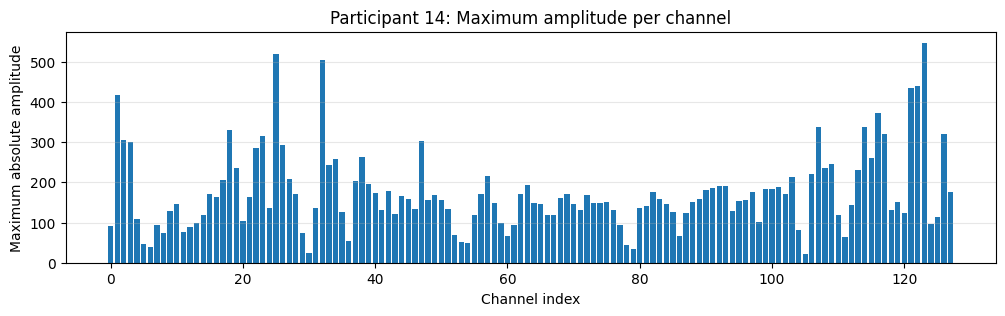


PARTICIPANT 41 | CLASS 0


,channel,max_absolute,samples_over_100,samples_over_200,samples_over_500
24,24,791.109985,14303,6239,223
25,25,695.260010,9887,2330,130
1,1,676.570007,12784,3529,369
7,7,623.960022,12309,4109,181
26,26,587.570007,5578,1418,56
121,121,566.960022,7770,2079,85
23,23,488.500000,5744,1616,0
22,22,488.179993,5730,1539,0
122,122,466.799988,6058,1891,0
0,0,452.480011,7232,1666,0


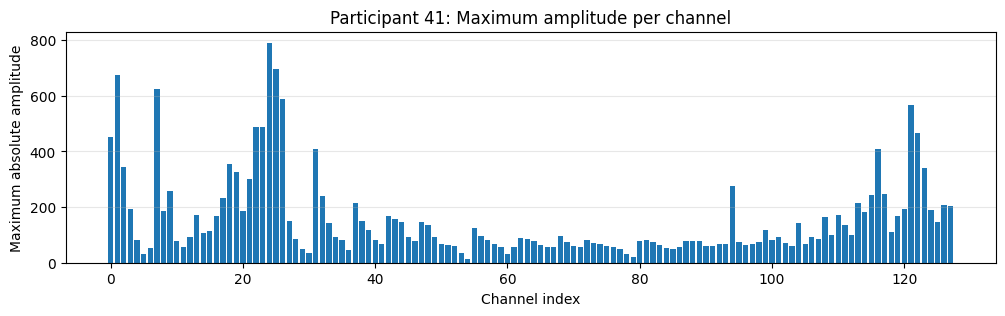


PARTICIPANT 24 | CLASS 0


,channel,max_absolute,samples_over_100,samples_over_200,samples_over_500
24,24,1351.400024,13492,5435,950
87,87,903.309998,4579,1408,131
80,80,836.440002,5064,1529,184
72,72,824.599976,4850,1507,173
126,126,765.619995,2651,186,69
7,7,718.109985,10469,3618,24
81,81,612.520020,3108,740,65
42,42,565.289978,267,14,5
122,122,558.440002,605,172,19
16,16,514.039978,2100,236,6


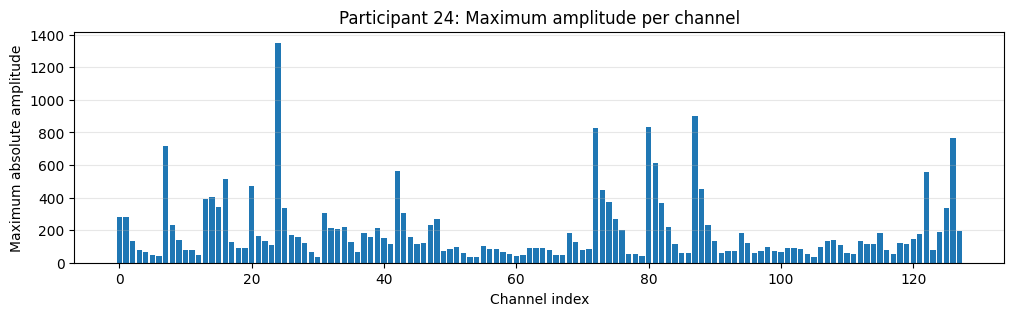


PARTICIPANT 48 | CLASS 0


,channel,max_absolute,samples_over_100,samples_over_200,samples_over_500
48,48,2954.469971,836,586,322
47,47,287.190002,202,58,0
44,44,285.440002,450,144,0
55,55,281.500000,292,57,0
98,98,180.600006,112,0,0
106,106,177.699997,186,0,0
94,94,164.330002,92,0,0
95,95,133.470001,46,0,0
56,56,114.480003,15,0,0
90,90,112.949997,15,0,0


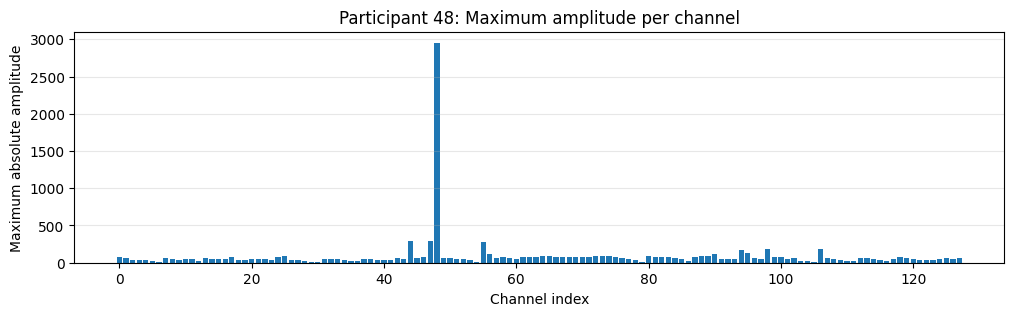


PARTICIPANT 20 | CLASS 1


,channel,max_absolute,samples_over_100,samples_over_200,samples_over_500
55,55,1211.270020,3480,905,151
85,85,61.540001,0,0,0
21,21,60.990002,0,0,0
13,13,56.480000,0,0,0
20,20,56.290001,0,0,0
87,87,50.310001,0,0,0
58,58,49.889999,0,0,0
16,16,49.709999,0,0,0
7,7,47.779999,0,0,0
22,22,46.349998,0,0,0


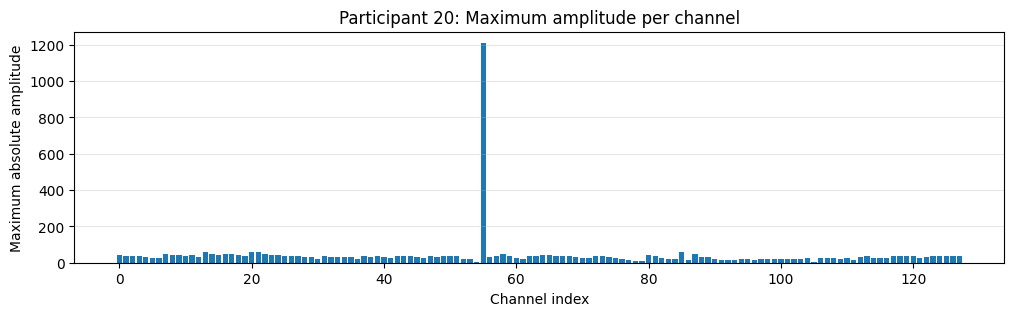

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data = np.load(DATA_PATH)
X = data["X"]
y = data["y"]
subject_id = data["subject_id"]

selected_subjects = [14, 41, 24, 48, 20]

for sid in selected_subjects:

    Xi = X[subject_id == sid]

    # Maximum absolute amplitude for each channel
    channel_max = np.max(np.abs(Xi), axis=(0, 2))

    # Number of samples exceeding thresholds per channel
    count_100 = np.sum(np.abs(Xi) > 100, axis=(0, 2))
    count_200 = np.sum(np.abs(Xi) > 200, axis=(0, 2))
    count_500 = np.sum(np.abs(Xi) > 500, axis=(0, 2))

    report = pd.DataFrame({
        "channel": np.arange(X.shape[1]),
        "max_absolute": channel_max,
        "samples_over_100": count_100,
        "samples_over_200": count_200,
        "samples_over_500": count_500
    })

    print(f"\nPARTICIPANT {sid} | CLASS {y[subject_id == sid][0]}")
    display(
        report.sort_values(
            "max_absolute", ascending=False
        ).head(10).round(2)
    )

    # Plot maximum absolute amplitude across channels
    plt.figure(figsize=(12, 3))
    plt.bar(report["channel"], report["max_absolute"])
    plt.title(f"Participant {sid}: Maximum amplitude per channel")
    plt.xlabel("Channel index")
    plt.ylabel("Maximum absolute amplitude")
    plt.grid(axis="y", alpha=0.3)
    plt.show()

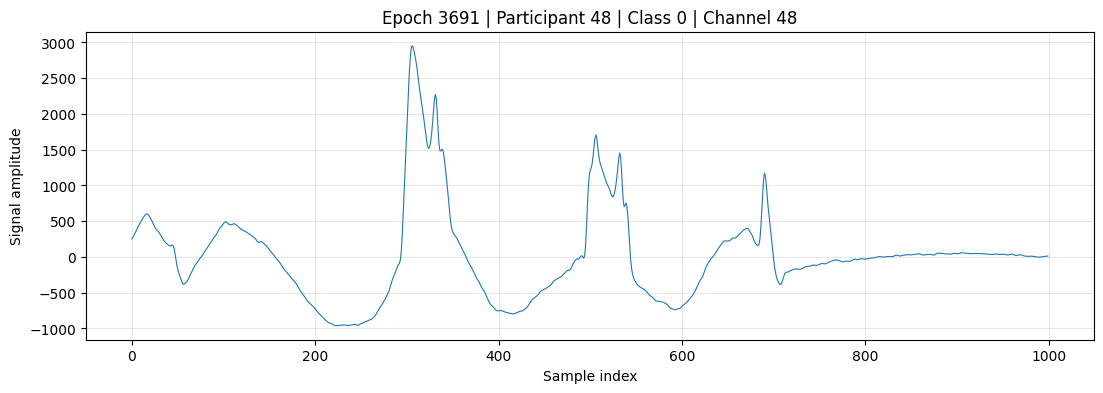

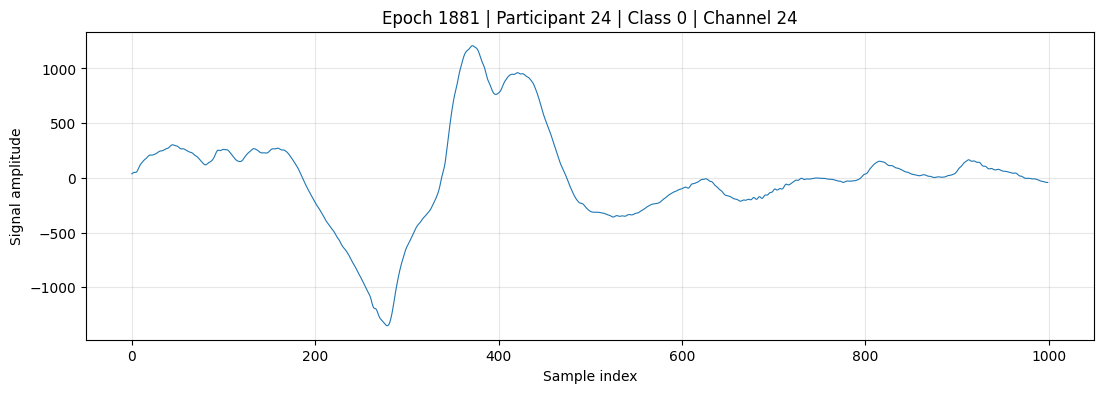

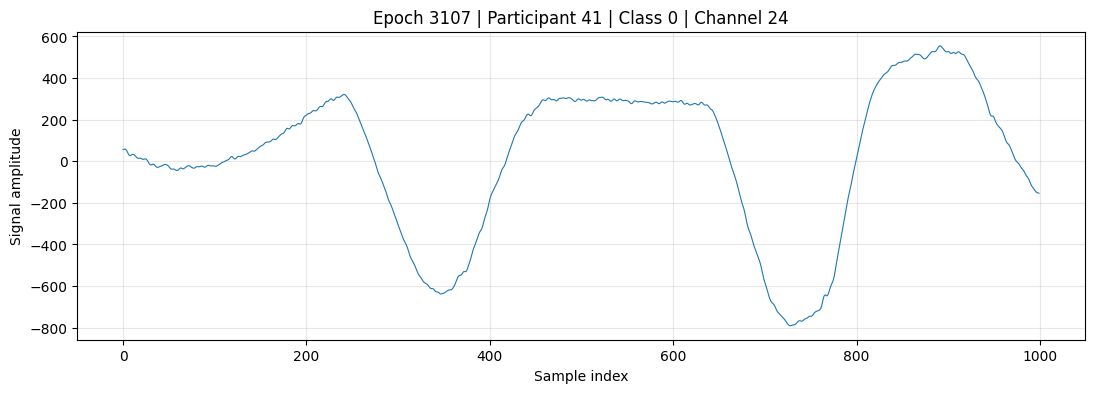

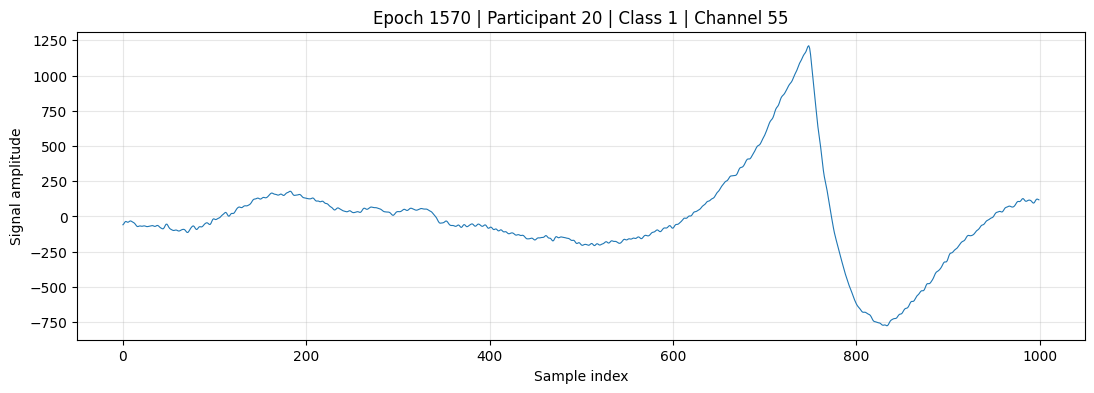

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

selected_epochs = [3691, 1881, 3107, 1570]

for epoch_idx in selected_epochs:

    epoch = X[epoch_idx]

    # Find the channel with the largest absolute amplitude
    channel_idx = np.unravel_index(
        np.argmax(np.abs(epoch)),
        epoch.shape
    )[0]

    signal = epoch[channel_idx]

    plt.figure(figsize=(13, 4))
    plt.plot(signal, linewidth=0.8)
    plt.title(
        f"Epoch {epoch_idx} | "
        f"Participant {subject_id[epoch_idx]} | "
        f"Class {y[epoch_idx]} | "
        f"Channel {channel_idx}"
    )
    plt.xlabel("Sample index")
    plt.ylabel("Signal amplitude")
    plt.grid(alpha=0.3)
    plt.show()

The detailed signal windows show values around selected high-amplitude peaks for five participant/channel combinations. The printed values and traces help distinguish an isolated transient from repeated high-amplitude behaviour across epochs.

In [ ]:
import numpy as np
import pandas as pd

# Inspect suspicious participant-channel combinations
checks = [
    (48, 48),
    (20, 55),
    (24, 24),
    (41, 24),
    (14, 123)
]

rows = []

for sid, ch in checks:
    mask = subject_id == sid
    subject_X = X[mask]
    channel_signal = subject_X[:, ch, :]

    peak_pos = np.unravel_index(
        np.argmax(np.abs(channel_signal)),
        channel_signal.shape
    )

    epoch_num, sample_num = peak_pos
    peak_value = channel_signal[epoch_num, sample_num]

    rows.append({
        "subject": sid,
        "channel": ch,
        "epochs": len(subject_X),
        "mean": channel_signal.mean(),
        "std": channel_signal.std(),
        "min": channel_signal.min(),
        "max": channel_signal.max(),
        "max_absolute": np.abs(channel_signal).max(),
        "samples_over_100": np.sum(np.abs(channel_signal) > 100),
        "samples_over_200": np.sum(np.abs(channel_signal) > 200),
        "peak_epoch_within_subject": epoch_num,
        "peak_sample": sample_num,
        "peak_value": peak_value
    })

    print(f"\n{'='*60}")
    print(f"PARTICIPANT {sid} | CHANNEL {ch}")
    print("Peak value:", peak_value)
    print("Peak sample:", sample_num)

    # Values around the largest peak
    start = max(0, sample_num - 10)
    end = min(1000, sample_num + 11)

    print("\nSignal around peak:")
    print(np.round(channel_signal[epoch_num, start:end], 2))

    # Compare the same epoch and sample across nearby channel indices
    print("\nNearby channels at the peak sample:")
    nearby = range(max(0, ch - 2), min(128, ch + 3))

    for nearby_ch in nearby:
        print(
            f"Channel {nearby_ch}: "
            f"{subject_X[epoch_num, nearby_ch, sample_num]:.2f}"
        )

channel_report = pd.DataFrame(rows)

print("\n\nCHANNEL INSPECTION SUMMARY")
display(channel_report.round(3))


PARTICIPANT 48 | CHANNEL 48
Peak value: 2954.4656
Peak sample: 306

Signal around peak:
[ 595.19  900.69 1199.2  1488.78 1785.06 2093.45 2394.27 2652.1  2836.06
 2933.81 2954.47 2922.92 2867.18 2803.83 2732.48 2645.33 2542.23 2434.89
 2336.19 2248.35 2163.38]

Nearby channels at the peak sample:
Channel 46: 71.82
Channel 47: 155.11
Channel 48: 2954.47
Channel 49: 26.64
Channel 50: 35.10

PARTICIPANT 20 | CHANNEL 55
Peak value: 1211.2678
Peak sample: 748

Signal around peak:
[1086.86 1098.8  1110.82 1124.94 1139.21 1150.44 1159.08 1169.95 1186.64
 1204.71 1211.27 1193.28 1147.84 1084.39 1016.64  952.33  890.48  826.87
  760.61  695.5   636.66]

Nearby channels at the peak sample:
Channel 53: 5.23
Channel 54: 1.90
Channel 55: 1211.27
Channel 56: 6.43
Channel 57: 7.01

PARTICIPANT 24 | CHANNEL 24
Peak value: -1351.402
Peak sample: 279

Signal around peak:
[-1251.59 -1272.13 -1286.6  -1296.66 -1305.32 -1314.55 -1324.62 -1334.76
 -1343.76 -1350.06 -1351.4  -1345.14 -1329.32 -1303.59 -1269.

,subject,channel,epochs,mean,std,min,max,max_absolute,samples_over_100,samples_over_200,peak_epoch_within_subject,peak_sample,peak_value
0,48,48,75,0.075,77.499001,-962.638977,2954.466064,2954.466064,836,586,64,306,2954.466064
1,20,55,75,0.420,63.134998,-774.838989,1211.267944,1211.267944,3480,905,60,748,1211.267944
2,24,24,75,-0.020,121.499001,-1351.401978,1207.793945,1351.401978,13492,5435,71,279,-1351.401978
3,41,24,75,0.030,108.814003,-791.112000,555.544006,791.112000,14303,6239,5,728,-791.112000
4,14,123,75,0.032,113.224998,-547.388000,519.518005,547.388000,19409,7307,47,313,-547.388000


The persistence analysis counts how often selected participant/channel pairs exceed amplitude thresholds across their epochs, and compares the same channels across the dataset. Repeated threshold exceedances are stronger evidence of persistent unusual amplitude behaviour than a single extreme sample, although they still require domain review before any channel is excluded.

In [ ]:
import numpy as np
import pandas as pd

checks = [
    (48, 48),
    (20, 55),
    (24, 24),
    (41, 24),
    (14, 123)
]

rows = []

for sid, ch in checks:
    mask = subject_id == sid
    subject_X = X[mask]
    channel_data = subject_X[:, ch, :]

    epoch_max = np.max(np.abs(channel_data), axis=1)
    epoch_std = np.std(channel_data, axis=1)
    epoch_over_100 = np.sum(np.abs(channel_data) > 100, axis=1)
    epoch_over_200 = np.sum(np.abs(channel_data) > 200, axis=1)

    rows.append({
        "subject": sid,
        "channel": ch,
        "total_epochs": len(channel_data),
        "epochs_max_over_100": np.sum(epoch_max > 100),
        "epochs_max_over_200": np.sum(epoch_max > 200),
        "epochs_max_over_500": np.sum(epoch_max > 500),
        "median_epoch_max": np.median(epoch_max),
        "p95_epoch_max": np.percentile(epoch_max, 95),
        "median_epoch_std": np.median(epoch_std),
        "total_samples_over_100": epoch_over_100.sum(),
        "total_samples_over_200": epoch_over_200.sum()
    })

report = pd.DataFrame(rows)

print("PERSISTENCE OF ABNORMAL AMPLITUDES")
display(report.round(3))

# Inspect the same channels in all participants
print("\nSAME CHANNELS ACROSS THE FULL DATASET")

channel_rows = []

for ch in sorted(set(ch for _, ch in checks)):
    for sid in np.unique(subject_id):
        mask = subject_id == sid
        values = X[mask, ch, :]

        channel_rows.append({
            "channel": ch,
            "subject": sid,
            "label": y[mask][0],
            "median_abs": np.median(np.abs(values)),
            "p99_abs": np.percentile(np.abs(values), 99),
            "max_abs": np.max(np.abs(values))
        })

channel_comparison = pd.DataFrame(channel_rows)

for ch in sorted(set(ch for _, ch in checks)):
    print(f"\nCHANNEL {ch}")
    display(
        channel_comparison[
            channel_comparison["channel"] == ch
        ].sort_values("max_abs", ascending=False).head(10).round(2)
    )

PERSISTENCE OF ABNORMAL AMPLITUDES


,subject,channel,total_epochs,epochs_max_over_100,epochs_max_over_200,epochs_max_over_500,median_epoch_max,p95_epoch_max,median_epoch_std,total_samples_over_100,total_samples_over_200
0,48,48,75,2,2,1,48.731998,64.234001,16.898001,836,586
1,20,55,75,37,7,1,98.588997,302.977997,34.810001,3480,905
2,24,24,75,60,33,7,164.826996,617.484009,62.747002,13492,5435
3,41,24,75,61,33,3,163.626007,475.770996,56.250999,14303,6239
4,14,123,75,63,43,1,231.927994,414.561005,97.830002,19409,7307



SAME CHANNELS ACROSS THE FULL DATASET

CHANNEL 24


,channel,subject,label,median_abs,p99_abs,max_abs
24,24,24,0,33.709999,528.909973,1351.400024
41,24,41,0,34.869999,404.630005,791.109985
18,24,18,1,13.330000,172.389999,784.880005
42,24,42,0,31.420000,116.379997,539.909973
31,24,31,0,18.440001,207.169998,484.670013
27,24,27,0,14.500000,259.369995,479.579987
36,24,36,0,16.170000,146.839996,450.040009
1,24,1,1,13.770000,235.630005,426.630005
2,24,2,1,27.860001,187.860001,426.140015
51,24,51,0,11.370000,74.570000,388.269989



CHANNEL 48


,channel,subject,label,median_abs,p99_abs,max_abs
101,48,48,0,12.020000,128.589996,2954.469971
90,48,37,0,19.610001,109.440002,580.599976
104,48,51,0,3.990000,19.570000,320.450012
55,48,2,1,7.180000,59.320000,265.899994
77,48,24,0,11.770000,62.480000,265.899994
79,48,26,0,7.500000,44.830002,177.559998
86,48,33,0,5.770000,27.700001,174.539993
60,48,7,1,7.560000,79.919998,170.389999
80,48,27,0,9.160000,62.090000,169.660004
75,48,22,1,6.450000,31.700001,165.529999



CHANNEL 55


,channel,subject,label,median_abs,p99_abs,max_abs
126,55,20,1,26.610001,219.949997,1211.270020
157,55,51,0,14.530000,60.689999,405.950012
113,55,7,1,9.720000,121.500000,320.910004
154,55,48,0,12.980000,52.549999,281.500000
108,55,2,1,6.240000,46.990002,205.710007
106,55,0,1,8.900000,56.650002,149.570007
143,55,37,0,17.290001,82.720001,147.380005
132,55,26,0,9.460000,74.010002,145.429993
133,55,27,0,7.560000,62.529999,145.309998
134,55,28,0,12.320000,77.870003,141.000000



CHANNEL 123


,channel,subject,label,median_abs,p99_abs,max_abs
173,123,14,1,43.400002,366.100006,547.390015
166,123,7,1,10.230000,181.630005,405.029999
210,123,51,0,4.980000,27.750000,396.350006
200,123,41,0,12.770000,209.539993,340.059998
177,123,18,1,7.450000,80.290001,326.950012
161,123,2,1,2.780000,40.500000,192.360001
185,123,26,0,6.590000,78.559998,146.570007
187,123,28,0,7.760000,91.620003,138.809998
163,123,4,1,4.020000,57.450001,129.240005
165,123,6,1,5.310000,49.520000,129.070007


The channel-relative analysis compares each target channel with the participant's other channels using median absolute amplitude and robust z-scores. The reported target-channel ratios and robust scores identify which combinations are most unusual relative to that participant. For example, participant 20/channel 55 has an amplitude ratio of 7.003 and robust z-score 12.859; participant 41/channel 24 has a ratio of 4.238 and robust z-score 7.094. These are diagnostic flags, not automatically validated artifact labels.

In [ ]:
import numpy as np
import pandas as pd

checks = [
    (48, 48),
    (20, 55),
    (24, 24),
    (41, 24),
    (14, 123)
]

rows = []

for sid, target_ch in checks:
    subject_X = X[subject_id == sid]

    # Median absolute amplitude for every channel
    channel_medians = np.median(
        np.abs(subject_X),
        axis=(0, 2)
    )

    participant_median = np.median(channel_medians)

    # Compare each channel against the participant's typical channel
    ratios = channel_medians / (participant_median + 1e-8)

    # Robust outlier score across channels
    channel_mad = np.median(
        np.abs(channel_medians - participant_median)
    )

    robust_z = (
        0.6745 * (channel_medians - participant_median)
        / (channel_mad + 1e-8)
    )

    target_ratio = ratios[target_ch]
    target_z = robust_z[target_ch]

    rows.append({
        "subject": sid,
        "target_channel": target_ch,
        "participant_median": participant_median,
        "target_channel_median": channel_medians[target_ch],
        "amplitude_ratio": target_ratio,
        "robust_z_score": target_z,
        "channels_ratio_above_3": np.sum(ratios > 3),
        "channels_ratio_above_5": np.sum(ratios > 5)
    })

    print(f"\nPARTICIPANT {sid}")
    print("Target channel:", target_ch)

    top_channels = pd.DataFrame({
        "channel": np.arange(128),
        "median_absolute_amplitude": channel_medians,
        "ratio_to_participant_median": ratios,
        "robust_z_score": robust_z
    })

    display(
        top_channels.sort_values(
            "median_absolute_amplitude",
            ascending=False
        ).head(10).round(3)
    )

print("\nTARGET CHANNEL COMPARISON")
display(pd.DataFrame(rows).round(3))


PARTICIPANT 48
Target channel: 48


,channel,median_absolute_amplitude,ratio_to_participant_median,robust_z_score
89,89,18.851000,2.223,2.335
88,88,17.812000,2.101,2.101
95,95,17.441000,2.057,2.018
74,74,16.959999,2.000,1.910
94,94,16.872000,1.990,1.890
82,82,16.195000,1.910,1.737
90,90,15.897000,1.875,1.670
98,98,15.829000,1.867,1.655
69,69,15.807000,1.864,1.650
64,64,15.720000,1.854,1.630



PARTICIPANT 20
Target channel: 55


,channel,median_absolute_amplitude,ratio_to_participant_median,robust_z_score
55,55,26.611,7.003,12.859
13,13,8.995,2.367,2.929
20,20,8.124,2.138,2.438
16,16,8.107,2.133,2.428
7,7,8.029,2.113,2.384
8,8,7.324,1.927,1.987
21,21,7.048,1.855,1.831
14,14,6.922,1.822,1.760
15,15,6.435,1.693,1.485
24,24,6.356,1.673,1.441



PARTICIPANT 24
Target channel: 24


,channel,median_absolute_amplitude,ratio_to_participant_median,robust_z_score
24,24,33.712002,4.149,5.463
7,7,25.920000,3.190,3.799
13,13,23.232000,2.859,3.226
87,87,17.138000,2.109,1.924
72,72,16.448000,2.024,1.777
80,80,16.271999,2.003,1.739
20,20,15.851000,1.951,1.650
126,126,15.502000,1.908,1.575
16,16,15.092000,1.857,1.488
81,81,15.010000,1.847,1.470


... (2 outputs left out)


PARTICIPANT 14
Target channel: 123


,channel,median_absolute_amplitude,ratio_to_participant_median,robust_z_score
25,25,43.806999,2.679,3.943
123,123,43.395000,2.654,3.884
32,32,43.201000,2.642,3.856
1,1,38.335999,2.344,3.158
122,122,34.632000,2.118,2.625
14,14,33.771000,2.065,2.502
117,117,31.746000,1.941,2.211
23,23,31.259001,1.911,2.141
116,116,29.759001,1.820,1.926
121,121,28.945000,1.770,1.809



TARGET CHANNEL COMPARISON


,subject,target_channel,participant_median,target_channel_median,amplitude_ratio,robust_z_score,channels_ratio_above_3,channels_ratio_above_5
0,48,48,8.478000,12.018000,1.417,0.797,0,0
1,20,55,3.800000,26.611000,7.003,12.859,1,1
2,24,24,8.125000,33.712002,4.149,5.463,2,0
3,41,24,8.229000,34.872002,4.238,7.094,3,0
4,14,123,16.353001,43.395000,2.654,3.884,0,0


The final signal summary reports median baseline, centred variability, and high-percentile amplitude statistics for the selected combinations. It shows that some channels have large within-epoch variability, including participant 48/channel 48 in a particular epoch. These findings provide context for the model's classification difficulty and indicate that signal-quality review may be useful; no revised dataset is produced in these cells.

In [ ]:
import numpy as np
import pandas as pd

checks = [
    (48, 48),
    (20, 55),
    (24, 24),
    (41, 24),
    (14, 123)
]

rows = []

for sid, ch in checks:
    subject_X = X[subject_id == sid]
    signal = subject_X[:, ch, :]

    for epoch_idx in range(len(signal)):
        epoch = signal[epoch_idx]

        baseline = np.median(epoch)
        centered = epoch - baseline

        rows.append({
            "subject": sid,
            "channel": ch,
            "epoch": epoch_idx,
            "baseline_median": baseline,
            "centered_std": np.std(centered),
            "centered_p99": np.percentile(np.abs(centered), 99),
            "centered_max": np.max(np.abs(centered)),
            "original_std": np.std(epoch)
        })

epoch_detail = pd.DataFrame(rows)

print("SUMMARY BY PARTICIPANT AND CHANNEL")

summary = epoch_detail.groupby(
    ["subject", "channel"]
).agg(
    median_baseline=("baseline_median", "median"),
    median_centered_std=("centered_std", "median"),
    median_centered_p99=("centered_p99", "median"),
    p95_centered_p99=("centered_p99", lambda x: np.percentile(x, 95)),
    median_original_std=("original_std", "median")
).reset_index()

display(summary.round(3))

print("\nEPOCHS WITH THE LARGEST CENTERED AMPLITUDES")

display(
    epoch_detail.sort_values(
        "centered_p99", ascending=False
    ).groupby(
        ["subject", "channel"]
    ).head(5).sort_values(
        ["subject", "centered_p99"],
        ascending=[True, False]
    ).round(3)
)

SUMMARY BY PARTICIPANT AND CHANNEL


,subject,channel,median_baseline,median_centered_std,median_centered_p99,p95_centered_p99,median_original_std
0,14,123,0.198,97.830002,219.212006,413.705994,97.830002
1,20,55,0.831,34.810001,87.995003,291.127014,34.810001
2,24,24,0.562,62.747002,157.490005,627.341003,62.747002
3,41,24,-1.334,56.250999,147.317993,489.332001,56.250999
4,48,48,0.931,16.898001,42.119999,55.334999,16.898001



EPOCHS WITH THE LARGEST CENTERED AMPLITUDES


,subject,channel,epoch,baseline_median,centered_std,centered_p99,centered_max,original_std
347,14,123,47,22.725000,246.996002,567.411011,570.112976,246.996002
362,14,123,62,-26.316999,170.352997,423.984009,434.726013,170.352997
338,14,123,38,10.914000,169.854004,421.684998,427.378998,169.854004
316,14,123,16,-15.215000,175.128998,414.122009,416.451996,175.128998
315,14,123,15,5.225000,127.737000,413.528015,418.553009,127.737000
135,20,55,60,-48.493000,333.096008,1159.458008,1259.760986,333.096008
124,20,55,49,11.519000,166.011993,390.751007,400.384003,166.011993
97,20,55,22,0.741000,116.766998,353.181000,423.265991,116.766998
133,20,55,58,2.903000,110.128998,320.152008,336.458008,110.128998
145,20,55,70,-1.248000,84.449997,278.687988,291.122009,84.449997


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from pathlib import Path

RAW_DIR = Path(
    "/content/drive/MyDrive/CDL-MDDNet/raw/EEG_128channels_resting_lanzhou_2015"
)

mat_files = list(RAW_DIR.rglob("*.mat")) if RAW_DIR.exists() else []

print("Raw directory exists:", RAW_DIR.exists())
print("Number of MAT files:", len(mat_files))

for f in mat_files[:5]:
    print(f.name)

Raw directory exists: False
Number of MAT files: 0


The targeted model tests pass for the tested forward-pass configurations, channel-count handling, DANN and non-DANN outputs, and parameter budget. The test output reports 27,031 inference parameters for the V2 test model. These are software tests of the V2 implementation and should not be confused with the 25,627 trainable-parameter count reported for the separate `CDLMDDNet` experiment.

In [ ]:
!python -m unittest discover -s tests -p "test_cdl_mddnet_v2.py" -v

test_forward_train_with_dann_head (test_cdl_mddnet_v2.TestCDLMDDNetV2.test_forward_train_with_dann_head) ... ok
test_forward_train_without_dann (test_cdl_mddnet_v2.TestCDLMDDNetV2.test_forward_train_without_dann) ... ok
test_output_shape_128_channels (test_cdl_mddnet_v2.TestCDLMDDNetV2.test_output_shape_128_channels) ... ok
test_output_shape_32_channels (test_cdl_mddnet_v2.TestCDLMDDNetV2.test_output_shape_32_channels) ... ok
test_parameter_budget (test_cdl_mddnet_v2.TestCDLMDDNetV2.test_parameter_budget) ... V2 inference parameters: 27,031
ok
test_rejects_wrong_channel_count (test_cdl_mddnet_v2.TestCDLMDDNetV2.test_rejects_wrong_channel_count) ... ok

----------------------------------------------------------------------
Ran 6 tests in 0.558s

OK


### Test-discovery note

A later broad `unittest discover` command reported `Ran 0 tests` and `NO TESTS RAN`. This means that command's discovery pattern did not find tests; it is not a passing test result. The valid software checks retained in this notebook are the earlier `pytest` run (93 passed) and the targeted V2 test run (6 passed). The zero-discovery command is omitted to avoid presenting it as a successful test.


In [ ]:
from pathlib import Path

CODE_DIR = Path("/content/drive/MyDrive/CDL-MDDNet/source_code")

for file in CODE_DIR.rglob("*.py"):
    print(file.relative_to(CODE_DIR))

src/__init__.py
tests/test_data_pipeline.py
tests/test_model_params.py
tests/test_normalizer.py
tests/test_no_subject_leakage.py
tests/test_results_table.py
tests/test_splits.py
tests/test_training.py
tests/test_cdl_mddnet_v2.py
src/app/__init__.py
src/data/load_modma.py
src/data/normalize.py
src/data/preprocess.py
src/data/__init__.py
src/eval/benchmark.py
src/eval/results_table.py
src/eval/update_slides.py
src/eval/__init__.py
src/explain/__init__.py
src/models/cdl_mddnet.py
src/models/__init__.py
src/models/cdl_mddnet_v2.py
src/training/config.py
src/training/run_experiment.py
src/training/splits.py
src/training/trainer.py
src/training/__init__.py


In [ ]:
%cd /content/drive/MyDrive/CDL-MDDNet/source_code

!python -m src.training.run_experiment --help

/content/drive/MyDrive/CDL-MDDNet/source_code
usage: run_experiment.py [-h] [--config CONFIG] [--model MODEL]
                         [--protocol {kfold10,loso}] [--experiment EXPERIMENT]
                         [--data DATA] [--runs-dir RUNS_DIR]
                         [--n-folds N_FOLDS] [--val-fraction VAL_FRACTION]
                         [--epochs EPOCHS] [--batch-size BATCH_SIZE] [--lr LR]
                         [--weight-decay WEIGHT_DECAY] [--patience PATIENCE]
                         [--seed SEED] [--split-seed SPLIT_SEED]
                         [--device DEVICE] [--num-workers NUM_WORKERS]
                         [--no-amp] [--no-class-weights] [--use-dann |
                         --no-dann] [--dann-gamma DANN_GAMMA]
                         [--dann-weight DANN_WEIGHT]
                         [--channels CHANNELS [CHANNELS ...]]
                         [--channel-ranking CHANNEL_RANKING]
                         [--top-k-channels TOP_K_CHANNELS]
               

In [ ]:
from pathlib import Path
import json

RUNS_DIR = Path("/content/drive/MyDrive/CDL-MDDNet/runs")

for folder in RUNS_DIR.iterdir():
    if folder.is_dir() and "exp07" in folder.name.lower():
        print("\nExperiment folder:", folder)
        for file in folder.rglob("*.json"):
            print("\nJSON file:", file)
            try:
                print(json.dumps(json.loads(file.read_text()), indent=2))
            except Exception as e:
                print("Could not read:", e)


Experiment folder: /content/drive/MyDrive/CDL-MDDNet/runs/exp07_cdl_erm_lr3e4_wd1e3

JSON file: /content/drive/MyDrive/CDL-MDDNet/runs/exp07_cdl_erm_lr3e4_wd1e3/run_config.json
{
  "config": {
    "experiment": "exp07_cdl_erm_lr3e4_wd1e3",
    "model": "src.models.cdl_mddnet:CDLMDDNet",
    "protocol": "kfold10",
    "data_path": "/content/drive/MyDrive/CDL-MDDNet/modma_epochs.npz",
    "runs_dir": "/content/drive/MyDrive/CDL-MDDNet/runs",
    "n_folds": 10,
    "val_fraction": 0.15,
    "seed": 42,
    "split_seed": 0,
    "epochs": 40,
    "batch_size": 32,
    "lr": 0.0003,
    "weight_decay": 0.001,
    "optimizer": "adamw",
    "scheduler": "cosine",
    "early_stopping_patience": 8,
    "early_stopping_min_delta": 0.0001,
    "class_weighted_loss": true,
    "grad_clip_norm": 1.0,
    "use_dann": false,
    "dann_gamma": 10.0,
    "dann_loss_weight": 1.0,
    "use_amp": true,
    "deterministic": true,
    "device": "auto",
    "num_workers": 0,
    "n_classes": 2
  },
  "data_p

## 12. LOSO Baseline Results and Confusion Matrix Analysis

The project inventory summarises the dataset tensors, source modules, experiment folders, and the saved experiment configuration. The metadata confirms the class coding and the 53-participant structure used by the LOSO runs.

In [ ]:

from pathlib import Path
import numpy as np
import json

PROJECT = Path("/content/drive/MyDrive/CDL-MDDNet")
SOURCE = PROJECT / "source_code"
DATA = PROJECT / "modma_epochs.npz"
RUNS = PROJECT / "runs"

print("=" * 65)
print("1. DATASET STRUCTURE")
print("=" * 65)

data = np.load(DATA, allow_pickle=True)

for key in data.files:
    arr = data[key]
    print(f"{key}: shape={arr.shape}, dtype={arr.dtype}")

    if arr.size <= 10:
        print("  Values:", arr)

print("\n" + "=" * 65)
print("2. PARTICIPANT AND LABEL INFORMATION")
print("=" * 65)

for key in data.files:
    arr = data[key]

    if arr.ndim == 1 and arr.size == 4002:
        print(f"\nPossible participant/label field: {key}")
        print("Unique values:", len(np.unique(arr)))
        print("Sample:", arr[:10])

        if len(np.unique(arr)) <= 10:
            print("Value counts:",
                  dict(zip(*np.unique(arr, return_counts=True))))

print("\n" + "=" * 65)
print("3. TRAINING SOURCE FILES")
print("=" * 65)

for folder in ["src/data", "src/training", "src/models"]:
    path = SOURCE / folder
    print(f"\n{folder}")

    if path.exists():
        for file in sorted(path.rglob("*.py")):
            print(" ", file.relative_to(SOURCE))

print("\n" + "=" * 65)
print("4. EXISTING EXPERIMENT FOLDERS")
print("=" * 65)

for folder in sorted(RUNS.iterdir()):
    if folder.is_dir():
        print(folder.name)

print("\n" + "=" * 65)
print("5. EXPERIMENT 7 CONFIGURATION")
print("=" * 65)

config_path = RUNS / "exp07_cdl_erm_lr3e4_wd1e3" / "run_config.json"

if config_path.exists():
    print(json.dumps(json.loads(config_path.read_text()), indent=2))
else:
    print("Experiment 7 config not found at expected path.")


1. DATASET STRUCTURE
X: shape=(4002, 128, 1000), dtype=float32
y: shape=(4002,), dtype=int64
subject_id: shape=(4002,), dtype=int64
ch_names: shape=(128,), dtype=<U8
subject_str_id: shape=(4002,), dtype=<U16

2. PARTICIPANT AND LABEL INFORMATION

Possible participant/label field: y
Unique values: 2
Sample: [1 1 1 1 1 1 1 1 1 1]
Value counts: {np.int64(0): np.int64(2192), np.int64(1): np.int64(1810)}

Possible participant/label field: subject_id
Unique values: 53
Sample: [0 0 0 0 0 0 0 0 0 0]

Possible participant/label field: subject_str_id
Unique values: 53
Sample: ['02010002' '02010002' '02010002' '02010002' '02010002' '02010002'
 '02010002' '02010002' '02010002' '02010002']

3. TRAINING SOURCE FILES

src/data
  src/data/__init__.py
  src/data/load_modma.py
  src/data/normalize.py
  src/data/preprocess.py

src/training
  src/training/__init__.py
  src/training/config.py
  src/training/run_experiment.py
  src/training/splits.py
  src/training/trainer.py

src/models
  src/models/__init

In [ ]:
import numpy as np

print("Variables with 53 values:")
print("--------------------------")

for name, value in globals().copy().items():
    try:
        arr = np.asarray(value)
        if arr.ndim == 1 and len(arr) == 53:
            print(f"{name} | Shape: {arr.shape} | Dtype: {arr.dtype}")
    except:
        pass

Variables with 53 values:
--------------------------


In [ ]:
import numpy as np

print("ALL ARRAYS AND LISTS IN MEMORY")
print("=" * 60)

for name, value in globals().copy().items():
    try:
        arr = np.asarray(value)
        if arr.ndim >= 1 and arr.size > 1:
            print(f"{name:40} Shape: {arr.shape} | Type: {arr.dtype}")
    except:
        pass

ALL ARRAYS AND LISTS IN MEMORY
_ih                                      Shape: (5,) | Type: <U902
In                                       Shape: (5,) | Type: <U902


In [ ]:
import os

runs_dir = "/content/drive/MyDrive/CDL-MDDNet/runs"

print("Does runs directory exist?", os.path.exists(runs_dir))

for root, dirs, files in os.walk(runs_dir):
    level = root.replace(runs_dir, "").count(os.sep)
    print("  " * level + os.path.basename(root) + "/")

    for file in files:
        print("  " * (level + 1) + file)

Does runs directory exist? True
runs/
  final_experiment_configurations.csv
  final_participant_level_results.csv
  final_verified_results.csv
  final_paired_comparison_53_participants.csv
  cdl_mddnet_kfold10_dann/
    run_config.json
    training_summary.csv
    participant_level_preds.csv
    combined_preds.csv
    fold_0/
      normalizer_stats.npz
      train_log.csv
      model.pt
      train_checkpoint.pt
      preds.csv
      fold_meta.json
    fold_1/
      normalizer_stats.npz
      train_log.csv
      model.pt
      train_checkpoint.pt
      preds.csv
      fold_meta.json
    fold_2/
      normalizer_stats.npz
      train_log.csv
      model.pt
      train_checkpoint.pt
      preds.csv
      fold_meta.json
    fold_3/
      normalizer_stats.npz
      train_log.csv
      model.pt
      train_checkpoint.pt
      preds.csv
      fold_meta.json
    fold_4/
      normalizer_stats.npz
      train_log.csv
      model.pt
      train_checkpoint.pt
      preds.csv
      fold_meta.json

The saved LOSO baseline prediction file contains one row per participant. `p_mdd` is the participant-level predicted probability of MDD, `n_epochs` is the number of epochs contributing to that participant's score, and `y_pred` is the thresholded prediction. The first ten rows illustrate how the participant-level probabilities map to predicted classes.

In [ ]:
import pandas as pd
import os

file_path = "/content/drive/MyDrive/CDL-MDDNet/runs/cdl_mddnet_loso_baseline/participant_level_preds.csv"

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 10 rows:")
display(df.head(10))

Dataset shape: (53, 5)

Column names:
['subject_id', 'y_true', 'p_mdd', 'n_epochs', 'y_pred']

First 10 rows:


,subject_id,y_true,p_mdd,n_epochs,y_pred
0,0,1,0.470960,75,0
1,1,1,0.433024,75,0
2,2,1,0.390351,75,0
3,3,1,0.494226,78,0
4,4,1,0.571036,82,1
5,5,1,0.585557,75,1
6,6,1,0.368240,75,0
7,7,1,0.573319,75,1
8,8,1,0.399635,75,0
9,9,1,0.499210,75,0


For the LOSO baseline, the confusion matrix is `[[10, 19], [14, 10]]` when rows are actual HC/MDD and columns are predicted HC/MDD. Thus, 10 HC participants and 10 MDD participants are correctly classified; 19 HC participants are false positives and 14 MDD participants are false negatives. Accuracy is 0.3774, sensitivity/recall for MDD is 0.4167, specificity is 0.3448, F1-score is 0.3774, and ROC-AUC is 0.3405. These values indicate poor discrimination on unseen participants in this LOSO baseline run.

In [ ]:
import pandas as pd
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report

file_path = "/content/drive/MyDrive/CDL-MDDNet/runs/cdl_mddnet_loso_baseline/participant_level_preds.csv"

df = pd.read_csv(file_path)

y_true = df["y_true"].astype(int)
y_pred = df["y_pred"].astype(int)
y_prob = df["p_mdd"].astype(float)

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

print("LOSO BASELINE - CONFUSION MATRIX")
print("--------------------------------")
print("                 Predicted HC   Predicted MDD")
print(f"Actual HC             {tn:2d}              {fp:2d}")
print(f"Actual MDD            {fn:2d}              {tp:2d}")

print("\nTN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

print("\nPERFORMANCE METRICS")
print("--------------------------------")
print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Precision:", round(precision_score(y_true, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_true, y_pred, zero_division=0), 4))
print("Specificity:", round(tn / (tn + fp), 4))
print("F1-score:", round(f1_score(y_true, y_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_true, y_prob), 4))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_true, y_pred,
    labels=[0, 1],
    target_names=["HC", "MDD"],
    zero_division=0
))

print("Total participants:", len(df))

LOSO BASELINE - CONFUSION MATRIX
--------------------------------
                 Predicted HC   Predicted MDD
Actual HC             10              19
Actual MDD            14              10

TN: 10
FP: 19
FN: 14
TP: 10

PERFORMANCE METRICS
--------------------------------
Accuracy: 0.3774
Precision: 0.3448
Recall: 0.4167
Specificity: 0.3448
F1-score: 0.3774
ROC-AUC: 0.3405

CLASSIFICATION REPORT
              precision    recall  f1-score   support

          HC       0.42      0.34      0.38        29
         MDD       0.34      0.42      0.38        24

    accuracy                           0.38        53
   macro avg       0.38      0.38      0.38        53
weighted avg       0.38      0.38      0.38        53

Total participants: 53


In [ ]:

import os, json, csv
from pathlib import Path

roots = [Path("/content")]
drive = Path("/content/drive/MyDrive")
if drive.exists():
    roots.append(drive)

keywords = (
    "pred", "config", "fold_meta", "checkpoint", "model",
    "train_log", "normalizer", "result", "experiment",
    "metric", "summary", "test", "report"
)

report = []
report.append("========== PROJECT VERIFICATION AUDIT ==========")

for root in roots:
    report.append(f"\nROOT: {root}")

    for current, dirs, files in os.walk(root):
        dirs[:] = [d for d in dirs if d not in
                   {".cache", "__pycache__", ".git", "site-packages"}]

        for filename in files:
            path = Path(current) / filename
            if not any(k in filename.lower() for k in keywords):
                continue

            try:
                size = path.stat().st_size
                report.append(f"\nFILE: {path}\nSIZE: {size:,} bytes")

                if filename.endswith(".json"):
                    try:
                        data = json.loads(path.read_text())
                        report.append(json.dumps(data, indent=2, default=str)[:12000])
                    except Exception as e:
                        report.append(f"JSON ERROR: {e}")

                elif filename.endswith(".csv"):
                    try:
                        with open(path, newline="", encoding="utf-8-sig") as f:
                            reader = csv.reader(f)
                            header = next(reader, [])
                            count = sum(1 for _ in reader)
                        report.append(f"ROWS: {count}")
                        report.append(f"COLUMNS: {header}")
                    except Exception as e:
                        report.append(f"CSV ERROR: {e}")

                elif filename.endswith(".npz"):
                    try:
                        import numpy as np
                        data = np.load(path)
                        for key in data.files:
                            report.append(f"{key}: shape={data[key].shape}")
                    except Exception as e:
                        report.append(f"NPZ ERROR: {e}")

                elif filename.endswith((".pt", ".pth")):
                    try:
                        import torch
                        data = torch.load(path, map_location="cpu",
                                          weights_only=False)
                        if isinstance(data, dict):
                            report.append(f"CHECKPOINT KEYS: {list(data.keys())}")
                        else:
                            report.append(f"OBJECT TYPE: {type(data)}")
                    except Exception as e:
                        report.append(f"CHECKPOINT INFO: {e}")

            except Exception as e:
                report.append(f"READ ERROR: {e}")

output = Path("/content/verification_inventory.txt")
output.write_text("\n".join(report), encoding="utf-8")

print("\n".join(report))
print("\n========== AUDIT FILE CREATED ==========")
print(output)

try:
    from google.colab import files
    files.download(str(output))
except Exception:
    print("Download the file manually from /content/")


## 13. Discussion and Conclusion

Across the saved experiments, participant-level generalisation is the main limitation. The ERM K-fold baseline is stronger than the DANN K-fold run in the consolidated results, while both LOSO runs perform poorly on unseen participants. The signal diagnostics also reveal several high-amplitude participant/channel combinations that may warrant additional quality-control investigation.

The notebook supports the conclusion that the current implementation and saved configurations do not yet provide robust MDD-versus-HC discrimination under the stricter LOSO protocol. The results should be presented as experimental findings rather than as a clinically validated diagnostic system. Further work could investigate signal-quality handling, participant-level generalisation, and more reliable evaluation on independent cohorts; those steps are recommendations and are not experiments performed in this notebook.
